# Fair Readmission Prediction with Explicit Models of Missing Clinical Data
**AFGML Laboratory (ICT 5143) — Capstone Problem 2** · UCI *Diabetes 130-US Hospitals 1999–2008* (dataset 296)

This notebook is organised so that every cell maps to a requirement in the problem statement. Run it top to bottom.

| § | Content | Problem-2 requirement covered |
|---|---|---|
| 1–3 | Setup, provenance, cohort, patient-disjoint split, discretisation fitted on train only | data provenance, leakage prevention, splitting |
| 4 | Pre-registration block | model selection, multiple comparisons |
| 5 | Metrics library (group tables, ΔEOpp/ΔEOdds/ΔDP, Rsel, small-group flags, calibration) | fairness metrics, small groups |
| 6 | Natural-missingness audit | Exp. 1 |
| 7–8 | Factor/variable-elimination library, Bayesian networks with observation nodes, **EM**, exact inference | graphical model, EM, VE |
| 9 | Correctness tests: normalisation, scopes, EM = MLE, VE = brute force = pgmpy VE = **clique tree** | graphical-model correctness |
| 10–12 | Baselines, fairness baselines, **proposed missingness-aware threshold selection** | Exp. 2, contribution |
| 13–15 | Masking generator (MCAR/MAR/MNAR/group-dependent), shift grid, **confirmatory test (patient bootstrap + Holm)** | Exp. 3–4 |
| 16 | Fairness–utility–capacity trade-offs | Exp. 5 |
| 17–18 | Ablations, robustness | ablation + robustness requirements |
| 19–20 | Graph analysis (d-separation, Markov blankets), calibration & probabilistic metrics | graph analysis, probabilistic metrics |
| 21 | Ethics, assumptions register, data/model cards, output bundle | deliverables |

Set `QUICK = True` in cell 1 for a ~10-minute smoke test (2 seeds, 100 bootstrap draws, one masking rate). The full run uses 5 seeds, 1,000 bootstrap draws and rates 10/30/50 %.

In [1]:
# ============================================================
# 1. SETUP, CONFIGURATION, REPRODUCIBILITY
# ============================================================
import os, sys, json, time, math, hashlib, platform, itertools, warnings, zipfile, subprocess
from pathlib import Path
warnings.filterwarnings("ignore")

def _pip(*pk):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pk], check=False)
try:
    import pgmpy, fairlearn
except ImportError:
    _pip("pgmpy", "fairlearn")
    import pgmpy, fairlearn

import numpy as np, pandas as pd, scipy
import matplotlib
import matplotlib.pyplot as plt
import networkx as nx
from scipy import stats
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss, brier_score_loss
import sklearn

IN_COLAB = "google.colab" in sys.modules
QUICK = False                                   # <- set True for a fast smoke test
QUICK = bool(int(os.environ.get("P2_QUICK", int(QUICK))))

SEEDS   = [0, 1, 2, 3, 4] if not QUICK else [0, 1]     # >=5 seeds required for the full run
N_BOOT  = 1000 if not QUICK else 100                   # >=1000 required for the full run
RATES   = [0.10, 0.30, 0.50] if not QUICK else [0.30]
CAPS    = [0.10, 0.20, 0.30]                           # follow-up capacities
CAP     = 0.20                                         # primary capacity
MIN_N   = 30                                           # small-cell threshold (exploratory below this)
SPLIT_SEED = 42
PAT_BUDGET = 300 if not QUICK else 100                 # random-search budget of the proposed rule
EM_ITERS   = 12

OUT = Path(os.environ.get("P2_OUT", "/content/p2_outputs" if IN_COLAB else "p2_outputs"))
for sub in ["figures", "tables", "cards"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "font.size": 9})
def savefig(name):                     # always save BEFORE plt.show()
    plt.savefig(OUT / "figures" / name, dpi=200, bbox_inches="tight")
def savetab(df, name, index=True):
    df.to_csv(OUT / "tables" / name, index=index)

CONFIG = dict(QUICK=QUICK, SEEDS=SEEDS, N_BOOT=N_BOOT, RATES=RATES, CAPS=CAPS, CAP=CAP, MIN_N=MIN_N,
              SPLIT_SEED=SPLIT_SEED, PAT_BUDGET=PAT_BUDGET, EM_ITERS=EM_ITERS,
              python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__,
              sklearn=sklearn.__version__, scipy=scipy.__version__, pgmpy=pgmpy.__version__,
              fairlearn=fairlearn.__version__, networkx=nx.__version__)
(OUT / "config.json").write_text(json.dumps(CONFIG, indent=2))
(OUT / "requirements.txt").write_text(
    f"numpy=={CONFIG['numpy']}\npandas=={CONFIG['pandas']}\nscikit-learn=={CONFIG['sklearn']}\nscipy=={CONFIG['scipy']}\n"
    f"pgmpy=={CONFIG['pgmpy']}\nfairlearn=={CONFIG['fairlearn']}\nnetworkx=={CONFIG['networkx']}\nmatplotlib\n")
print(json.dumps(CONFIG, indent=2))

{
  "QUICK": false,
  "SEEDS": [
    0,
    1,
    2,
    3,
    4
  ],
  "N_BOOT": 1000,
  "RATES": [
    0.1,
    0.3,
    0.5
  ],
  "CAPS": [
    0.1,
    0.2,
    0.3
  ],
  "CAP": 0.2,
  "MIN_N": 30,
  "SPLIT_SEED": 42,
  "PAT_BUDGET": 300,
  "EM_ITERS": 12,
  "python": "3.13.16",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "sklearn": "1.6.1",
  "scipy": "1.16.3",
  "pgmpy": "1.1.2",
  "fairlearn": "0.15.0",
  "networkx": "3.7"
}


In [2]:
# ============================================================
# 2. DATA ACQUISITION AND PROVENANCE
# ============================================================
# Acquisition (no data are redistributed with this notebook):
#   https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008
#   -> download and unzip; place diabetic_data.csv and IDS_mapping.csv in one of the folders below.
if IN_COLAB:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception as e:
        print("Drive not mounted:", e)

def find_file(name):
    roots = [".", "/content", "/content/drive/MyDrive/afgml dataset", "/content/drive/MyDrive",
             "/mnt/user-data/uploads", str(Path.home())]
    for r in roots:
        p = Path(r) / name
        if p.exists():
            return p
    raise FileNotFoundError(f"{name} not found. Upload it next to the notebook (see acquisition note above).")

DATA_PATH = find_file("diabetic_data.csv")
try:
    IDS_PATH = find_file("IDS_mapping.csv")
except FileNotFoundError:
    IDS_PATH = None

# '?' is the dataset's own missing code; the string 'None' in A1Cresult means 'test not performed'.
# Both are converted EXPLICITLY (not relying on the pandas version's default NA list).
raw = pd.read_csv(DATA_PATH, keep_default_na=False, na_values=["?", "None"], dtype={"diag_1": str})
sha = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
PROVENANCE = dict(dataset="UCI Diabetes 130-US Hospitals for Years 1999-2008 (id 296)",
                  source="https://archive.ics.uci.edu/dataset/296", file=str(DATA_PATH.name),
                  sha256=sha, n_rows=int(raw.shape[0]), n_cols=int(raw.shape[1]),
                  license="Listed on the UCI page as CC BY 4.0 (verify before redistribution)",
                  note="Encounter-level data from 130 US hospitals; encounter_id order is NOT temporal order.")
print(json.dumps(PROVENANCE, indent=2))
print("\nA1Cresult value counts (None -> NaN):")
print(raw["A1Cresult"].value_counts(dropna=False))

Mounted at /content/drive
{
  "dataset": "UCI Diabetes 130-US Hospitals for Years 1999-2008 (id 296)",
  "source": "https://archive.ics.uci.edu/dataset/296",
  "file": "diabetic_data.csv",
  "sha256": "0689e7ec031237dc63031b938805c48377748761a3b26acab621567afa24df97",
  "n_rows": 101766,
  "n_cols": 50,
  "license": "Listed on the UCI page as CC BY 4.0 (verify before redistribution)",
  "note": "Encounter-level data from 130 US hospitals; encounter_id order is NOT temporal order."
}

A1Cresult value counts (None -> NaN):
A1Cresult
NaN     84748
>8       8216
Norm     4990
>7       3812
Name: count, dtype: int64


In [3]:
# ============================================================
# 3. COHORT CONSTRUCTION, LABEL, VARIABLES (documented recodings)
# ============================================================
# Exclusion: discharge dispositions that make readmission impossible/undefined (expired, hospice),
# identified from IDS_mapping.csv.
if IDS_PATH is not None:
    lines = IDS_PATH.read_text(encoding="utf-8-sig").splitlines()
    start = [i for i, l in enumerate(lines) if l.startswith("discharge_disposition_id")][0]
    rows = []
    for l in lines[start + 1:]:
        if l.strip() in ("", ","):
            break
        k, _, v = l.partition(",")
        rows.append((int(k), v.strip('"')))
    dis = pd.DataFrame(rows, columns=["id", "desc"])
    EXCL_IDS = dis[dis.desc.str.contains("Expired|Hospice", case=False)].id.tolist()
else:
    EXCL_IDS = [11, 13, 14, 19, 20, 21]
print("Excluded discharge_disposition_id:", EXCL_IDS)

n0 = len(raw)
df0 = raw[~raw.discharge_disposition_id.isin(EXCL_IDS)].copy()
n_excl = n0 - len(df0)

RACES   = ["AfricanAmerican", "Asian", "Caucasian", "Hispanic", "Other", "Unknown"]   # 'Unknown' = recorded as '?'
GENDERS = ["Female", "Male", "Unknown/Invalid"]
RACE_IDX = {r: i for i, r in enumerate(RACES)}
GEN_IDX  = {g: i for i, g in enumerate(GENDERS)}
RG_NAME  = {r * 10 + g: f"{RACES[r]}|{GENDERS[g]}" for r in range(6) for g in range(3)}

def icd_group(code):
    # Strack et al. (2014) diagnosis grouping, merged to 6 classes:
    # 0 circulatory, 1 diabetes, 2 respiratory, 3 digestive, 4 injury/musculoskeletal/genitourinary, 5 other (incl. neoplasms, V/E codes)
    if code is None or (isinstance(code, float) and np.isnan(code)):
        return 5
    s = str(code)
    if s.startswith("250"):
        return 1
    if s[0] in "VE":
        return 5
    try:
        v = float(s)
    except ValueError:
        return 5
    if 390 <= v <= 459 or int(v) == 785: return 0
    if 460 <= v <= 519 or int(v) == 786: return 2
    if 520 <= v <= 579 or int(v) == 787: return 3
    if 800 <= v <= 999 or 710 <= v <= 739 or 580 <= v <= 629 or int(v) == 788: return 4
    return 5
ICD_NAMES = ["circulatory", "diabetes", "respiratory", "digestive", "injury/msk/GU", "other"]

cohort = pd.DataFrame({
    "patient_nbr": df0.patient_nbr.values,
    "race_i":   df0.race.fillna("Unknown").map(RACE_IDX).values,
    "gender_i": df0.gender.map(GEN_IDX).values,
    "age_dec":  df0.age.str.extract(r"\[(\d+)-")[0].astype(int).values // 10,     # decade index 0..9
    "H": np.minimum(df0.number_inpatient.values, 2),                              # prior inpatient visits (0,1,2+)
    "P": np.minimum(df0.number_outpatient.values + df0.number_emergency.values, 2),  # prior outpatient+ED visits (0,1,2+)
    "C": df0.diag_1.map(icd_group).values,                                         # primary-diagnosis group
    "ND_raw": df0.number_diagnoses.astype(float).values,                           # measurement 1 (complete in the raw data)
    "XA": df0.A1Cresult.map({"Norm": 0, ">7": 1, ">8": 2}).fillna(-1).astype(int).values,  # measurement 2 (-1 = not measured)
    "y": (df0.readmitted == "<30").astype(int).values,                             # recorded readmission <30 days
}).reset_index(drop=True)

print(f"Raw encounters: {n0:,}  | excluded (expired/hospice): {n_excl:,}  | analysis encounters: {len(cohort):,}")
print(f"Unique patients: {cohort.patient_nbr.nunique():,}")
print(f"Y=1 prevalence: {cohort.y.mean():.4f}   A1C missing: {(cohort.XA < 0).mean():.3f}")
print("Gender 'Unknown/Invalid' rows kept as its own (tiny, exploratory) category:", int((cohort.gender_i == 2).sum()))
print("Race recorded as '?' kept as category 'Unknown':", int((cohort.race_i == 5).sum()))

DATA_CARD = f"""# Data card — Diabetes 130-US Hospitals (Problem 2)
- **Source / version**: {PROVENANCE['source']} · file `{PROVENANCE['file']}` · sha256 `{sha[:16]}…` · {n0:,} encounters × {raw.shape[1]} columns
- **Licence**: {PROVENANCE['license']}
- **Inclusion**: all encounters except discharge dispositions {EXCL_IDS} (expired/hospice; readmission undefined) → {n_excl:,} removed, {len(cohort):,} kept ({cohort.patient_nbr.nunique():,} patients).
- **Label**: Y=1 iff `readmitted == '<30'`; '>30' and 'NO' → Y=0. Absence of a recorded readmission is *not* proof of no readmission elsewhere.
- **Protected attributes** (recorded categories, not inferred): race (AfricanAmerican, Asian, Caucasian, Hispanic, Other, Unknown='?'), gender (incl. 3 'Unknown/Invalid'), age band (secondary).
- **Measurements with an observation indicator**: A1C result (naturally missing = test not performed, {(cohort.XA<0).mean():.1%}); number of diagnoses (complete in raw data; masked only in semi-synthetic experiments).
- **Covariates**: prior inpatient visits (0/1/2+), prior outpatient+ED visits (0/1/2+), primary-diagnosis group (6 classes).
- **Not used**: encounter_id order (not temporal), hospital identifiers (absent) → no hospital-level or temporal claims.
- **Unit of dependence**: patient (multiple encounters per patient) → all splits/bootstraps are patient-level.
"""
(OUT / "cards" / "data_card.md").write_text(DATA_CARD)

Excluded discharge_disposition_id: [11, 13, 14, 19, 20, 21]
Raw encounters: 101,766  | excluded (expired/hospice): 2,423  | analysis encounters: 99,343
Unique patients: 69,990
Y=1 prevalence: 0.1139   A1C missing: 0.831
Gender 'Unknown/Invalid' rows kept as its own (tiny, exploratory) category: 3
Race recorded as '?' kept as category 'Unknown': 2234


1356

In [4]:
# ============================================================
# 4. PATIENT-DISJOINT TRAIN / VALIDATION / TEST SPLIT + TRAIN-ONLY DISCRETISATION
# ============================================================
g1 = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SPLIT_SEED)
trv_idx, te_idx = next(g1.split(cohort, groups=cohort.patient_nbr))
trv = cohort.iloc[trv_idx]
g2 = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SPLIT_SEED)
tr_i, va_i = next(g2.split(trv, groups=trv.patient_nbr))
SPLITS = {"train": trv.iloc[tr_i], "val": trv.iloc[va_i], "test": cohort.iloc[te_idx]}

P_ = {k: set(v.patient_nbr) for k, v in SPLITS.items()}
assert not (P_["train"] & P_["val"]) and not (P_["train"] & P_["test"]) and not (P_["val"] & P_["test"]), "patient leakage!"
print({k: (len(v), v.patient_nbr.nunique(), round(v.y.mean(), 4)) for k, v in SPLITS.items()}, "(rows, patients, prevalence)")
print("Patient overlap between partitions: 0 (asserted)")

# --- discretisation: learned on TRAIN ONLY ---
def nd_edges(x, k):
    qs = np.quantile(x, np.linspace(0, 1, k + 1)[1:-1])
    return np.unique(qs)
def age_band(age_dec, scheme):
    a = np.asarray(age_dec)
    if scheme == 3:   # <50, 50-69, >=70
        return np.select([a < 5, a < 7], [0, 1], 2)
    if scheme == 5:   # <40, 40-59, 60-69, 70-79, >=80
        return np.select([a < 4, a < 6, a < 7, a < 8], [0, 1, 2, 3], 4)
    raise ValueError

def build_ds(df, edges, age_scheme=3):
    ND_raw = df.ND_raw.to_numpy(float)
    ds = dict(pid=df.patient_nbr.to_numpy(), race=df.race_i.to_numpy(), gender=df.gender_i.to_numpy(),
              age=age_band(df.age_dec.to_numpy(), age_scheme), age_dec=df.age_dec.to_numpy(),
              H=df.H.to_numpy(), P=df.P.to_numpy(), C=df.C.to_numpy(),
              ND_raw=ND_raw, ND=np.searchsorted(edges, ND_raw, side="left"),
              XA=df.XA.to_numpy(), y=df.y.to_numpy())
    ds["RA"] = (ds["XA"] >= 0).astype(int)
    ds["RN"] = (~np.isnan(ds["ND_raw"])).astype(int)
    ds["rg"] = ds["race"] * 10 + ds["gender"]
    ds["cards"] = dict(race=6, gender=3, age={3: 3, 5: 5}[age_scheme], H=3, P=3, C=6, ND=len(edges) + 1, XA=3)
    return ds

def make_all_ds(age_scheme=3, nd_k=3):
    edges = nd_edges(SPLITS["train"].ND_raw.to_numpy(), nd_k)       # TRAIN only
    return {k: build_ds(v, edges, age_scheme) for k, v in SPLITS.items()}, edges

DS, ND_EDGES = make_all_ds(3, 3)
print("number_diagnoses tertile edges (train):", ND_EDGES, "| cards:", DS["train"]["cards"])

{'train': (59814, 41994, np.float64(0.1145)), 'val': (19727, 13998, np.float64(0.1142)), 'test': (19802, 13998, np.float64(0.1119))} (rows, patients, prevalence)
Patient overlap between partitions: 0 (asserted)
number_diagnoses tertile edges (train): [7. 9.] | cards: {'race': 6, 'gender': 3, 'age': 3, 'H': 3, 'P': 3, 'C': 6, 'ND': 3, 'XA': 3}


## 4b. Pre-registration (frozen before any test outcome is inspected)
All thresholds, operating points, penalties and hyper-parameters are chosen on **train/validation only**. The test partition is used once per reported number.

In [5]:
PREREG = {
 "primary_predictive_metric": "Average precision (AP) on the frozen test split; recall@capacity as the decision-level utility",
 "primary_fairness_criterion": "Equality of opportunity: DeltaEOpp across race x gender intersections with >=30 positives; worst-group recall as companion",
 "secondary_criteria": ["DeltaEOdds", "DeltaDP + Rsel (diagnostic)", "group calibration (diagnostic)", "gaps within missingness patterns"],
 "decision": "D=1 prioritises the patient for a SIMULATED follow-up service; capacity 20% (primary), 10%/30% (robustness). Selection = top-k of the evaluated batch (fixed capacity).",
 "acceptable_utility_loss": "<=0.01 absolute loss in recall@20% vs. the LR+indicator reference at matched capacity",
 "protected attributes at prediction time": "NOT used by any scoring model; the group-aware EO threshold baseline is the only method that uses race x gender at decision time (flagged in all tables)",
 "primary_research_question": "Does explicit availability modelling (BN with observation nodes + marginalisation) reduce the deterioration of worst-group recall when missingness shifts?",
 "primary_shift": "train+validation under MAR@30% -> test under (a) same MAR@30% (no shift) and (b) MNAR@30% (shift) ; deterioration = wgr(no shift) - wgr(shift)",
 "confirmatory_family (Holm, m=3)": ["BN-marg vs LR-imp", "BN-marg vs LR-ind", "BN-marg vs BN-base"],
 "exploratory": "everything else (grid over mechanisms/rates, ablations, robustness, sub-group analyses)",
 "tuning_budget": "4 candidates per model family on VALIDATION AP under natural missingness, then frozen (LR: C; HGB: depth x lr; BN: smoothing strength)",
 "uncertainty": f"patient-level cluster bootstrap, B={N_BOOT}, paired across methods; seeds={SEEDS} measure algorithmic/masking variability only",
}
(OUT / "cards" / "preregistration.json").write_text(json.dumps(PREREG, indent=2))
print(json.dumps(PREREG, indent=2))

{
  "primary_predictive_metric": "Average precision (AP) on the frozen test split; recall@capacity as the decision-level utility",
  "primary_fairness_criterion": "Equality of opportunity: DeltaEOpp across race x gender intersections with >=30 positives; worst-group recall as companion",
  "secondary_criteria": [
    "DeltaEOdds",
    "DeltaDP + Rsel (diagnostic)",
    "group calibration (diagnostic)",
    "gaps within missingness patterns"
  ],
  "decision": "D=1 prioritises the patient for a SIMULATED follow-up service; capacity 20% (primary), 10%/30% (robustness). Selection = top-k of the evaluated batch (fixed capacity).",
  "acceptable_utility_loss": "<=0.01 absolute loss in recall@20% vs. the LR+indicator reference at matched capacity",
  "protected attributes at prediction time": "NOT used by any scoring model; the group-aware EO threshold baseline is the only method that uses race x gender at decision time (flagged in all tables)",
  "primary_research_question": "Does explicit 

In [6]:
# ============================================================
# 5. METRICS LIBRARY (shared notation: s_g, t_g, f_g; DeltaDP, DeltaEOpp, DeltaEOdds, Rsel)
# ============================================================
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return c - h, c + h

def group_table(y, d, g, names=None, min_n=MIN_N):
    """Per-group denominators and rates: s_g=P(D=1|g), t_g=P(D=1|Y=1,g), f_g=P(D=1|Y=0,g)."""
    rows = []
    for k in np.unique(g):
        m = g == k; yy, dd = y[m], d[m]
        n, npos = int(m.sum()), int(yy.sum()); nneg = n - npos
        rows.append(dict(group=names.get(k, k) if names else k, n=n, n_pos=npos, n_neg=nneg,
                         sel=dd.mean(), tpr=dd[yy == 1].mean() if npos else np.nan,
                         fpr=dd[yy == 0].mean() if nneg else np.nan,
                         ok_sel=n >= min_n, ok_tpr=npos >= min_n, ok_fpr=nneg >= min_n))
    t = pd.DataFrame(rows)
    t["exploratory"] = ~(t.ok_sel & t.ok_tpr & t.ok_fpr)
    return t

def fairness_summary(tab, adequate=True):
    if adequate:
        a, b, c = tab[tab.ok_sel], tab[tab.ok_tpr], tab[tab.ok_fpr]
    else:
        a = b = c = tab
    dp    = a.sel.max() - a.sel.min() if len(a) > 1 else np.nan
    eopp  = b.tpr.max() - b.tpr.min() if len(b) > 1 else np.nan
    fgap  = c.fpr.max() - c.fpr.min() if len(c) > 1 else np.nan
    eodds = np.nanmax([eopp, fgap]) if not (np.isnan(eopp) and np.isnan(fgap)) else np.nan
    rsel  = (a.sel.min() / a.sel.max()) if len(a) > 1 and a.sel.max() > 0 else np.nan   # undefined if denominator is 0
    return dict(dEOpp=eopp, dEOdds=eodds, dDP=dp, Rsel=rsel,
                worst_tpr=b.tpr.min() if len(b) else np.nan, n_groups_used=len(b), n_groups_total=len(tab))

def fair_fast(y, d, g):
    """Vectorised headline metrics over groups with >=MIN_N positives (TPR) / >=MIN_N rows (selection)."""
    u, inv = np.unique(g, return_inverse=True)
    n = np.bincount(inv); npos = np.bincount(inv, weights=y)
    tp = np.bincount(inv, weights=d * y); sel = np.bincount(inv, weights=d)
    ok = npos >= MIN_N; ok2 = n >= MIN_N
    tpr = tp[ok] / npos[ok]; s = sel[ok2] / n[ok2]
    return dict(wgr=tpr.min() if ok.any() else np.nan,
                dEOpp=tpr.max() - tpr.min() if ok.sum() > 1 else np.nan,
                dDP=s.max() - s.min() if ok2.sum() > 1 else np.nan)

def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))
def _jit(n, seed=123):                      # deterministic tie-breaking for discrete (BN) scores
    return np.random.default_rng(seed).uniform(0, 1e-9, n)
def decide_cap(score, cap, off=None):
    """Fixed-capacity decision: select the top `cap` fraction of the evaluated batch (off = additive logit offsets)."""
    z = logit(score) + (0 if off is None else off) + _jit(len(score))
    return (z >= np.quantile(z, 1 - cap)).astype(int)

def pred_metrics(y, s, d):
    sel = d.sum()
    return dict(AUROC=roc_auc_score(y, s), AP=average_precision_score(y, s),
                recall=(d * y).sum() / y.sum(), precision=(d * y).sum() / max(sel, 1),
                logloss=log_loss(y, np.clip(s, 1e-6, 1 - 1e-6)), brier=brier_score_loss(y, s))

def ece(y, p, bins=10):
    q = np.quantile(p, np.linspace(0, 1, bins + 1)); q[0] -= 1e-9; q[-1] += 1e-9
    b = np.digitize(p, q[1:-1]); tot = 0
    for k in range(bins):
        m = b == k
        if m.any(): tot += m.mean() * abs(y[m].mean() - p[m].mean())
    return tot

# ---- consistency check of my metric code against Fairlearn ----
from fairlearn.metrics import equalized_odds_difference, demographic_parity_difference, MetricFrame
from sklearn.metrics import recall_score
rng_ = np.random.default_rng(0)
yt = DS["test"]["y"]; dt = (rng_.random(len(yt)) < 0.2 + 0.2 * yt).astype(int); gt = DS["test"]["race"]
tab_ = group_table(yt, dt, gt, {i: r for i, r in enumerate(RACES)})
mine = fairness_summary(tab_, adequate=False)
fl_eodds = equalized_odds_difference(yt, dt, sensitive_features=gt, method="between_groups")
fl_dp = demographic_parity_difference(yt, dt, sensitive_features=gt, method="between_groups")
mf = MetricFrame(metrics=recall_score, y_true=yt, y_pred=dt, sensitive_features=gt).difference()
print(f"dEOdds mine={mine['dEOdds']:.6f} fairlearn={fl_eodds:.6f} | dDP mine={mine['dDP']:.6f} fairlearn={fl_dp:.6f} | dEOpp mine={mine['dEOpp']:.6f} fairlearn={mf:.6f}")
assert abs(mine['dEOdds'] - fl_eodds) < 1e-9 and abs(mine['dDP'] - fl_dp) < 1e-9 and abs(mine['dEOpp'] - mf) < 1e-9
print("Metric implementation agrees with Fairlearn.")

dEOdds mine=0.292308 fairlearn=0.292308 | dDP mine=0.028482 fairlearn=0.028482 | dEOpp mine=0.292308 fairlearn=0.292308
Metric implementation agrees with Fairlearn.



A1C availability by race
                     n  A1C_observed  ci_lo  ci_hi  readmit_rate_if_observed  readmit_rate_if_missing  exploratory
group                                                                                                             
AfricanAmerican  15065         0.184  0.178  0.190                     0.100                    0.120        False
Asian              506         0.206  0.173  0.243                     0.067                    0.119        False
Caucasian        59334         0.162  0.159  0.165                     0.101                    0.118        False
Hispanic          1646         0.250  0.229  0.271                     0.088                    0.111        False
Other             1174         0.214  0.191  0.238                     0.088                    0.104        False
Unknown           1816         0.186  0.169  0.205                     0.044                    0.091        False

A1C availability by gender
                     n  A1

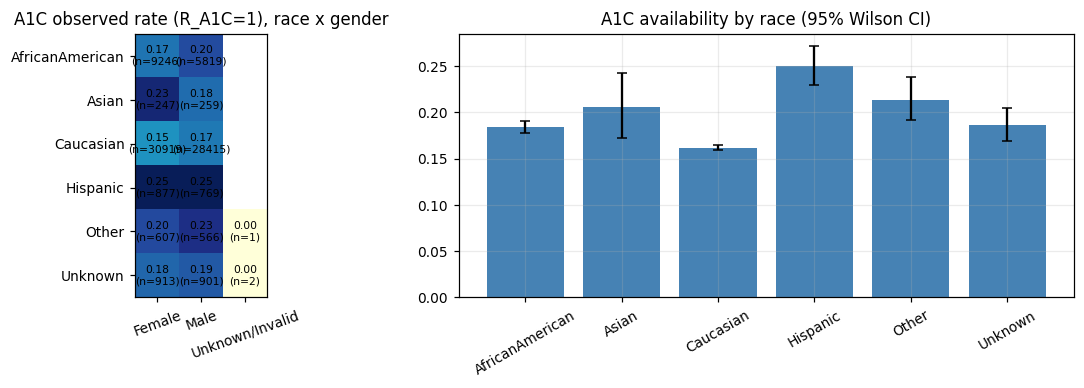

In [7]:
# ============================================================
# 6. EXPERIMENT 1 — NATURAL MISSINGNESS AUDIT (development data = train+val; descriptive only, nothing is fitted)
# ============================================================
dev = pd.concat([SPLITS["train"], SPLITS["val"]])
dev = dev.assign(RA=(dev.XA >= 0).astype(int), rg=dev.race_i * 10 + dev.gender_i,
                 ageb=age_band(dev.age_dec.to_numpy(), 3))

def rate_table(df, by, names=None):
    rows = []
    for k, t in df.groupby(by):
        n, obs = len(t), int(t.RA.sum()); lo, hi = wilson(obs, n)
        rows.append(dict(group=names.get(k, k) if names else k, n=n, A1C_observed=obs / n, ci_lo=lo, ci_hi=hi,
                         readmit_rate_if_observed=t.y[t.RA == 1].mean() if obs else np.nan,
                         readmit_rate_if_missing=t.y[t.RA == 0].mean() if obs < n else np.nan,
                         exploratory=n < MIN_N))
    return pd.DataFrame(rows).set_index("group")

aud_race   = rate_table(dev, "race_i", {i: r for i, r in enumerate(RACES)})
aud_gender = rate_table(dev, "gender_i", {i: r for i, r in enumerate(GENDERS)})
aud_rg     = rate_table(dev, "rg", RG_NAME)
aud_age    = rate_table(dev, "ageb", {0: "<50", 1: "50-69", 2: ">=70"})
for nm, t in [("race", aud_race), ("gender", aud_gender), ("age band", aud_age)]:
    print(f"\nA1C availability by {nm}"); print(t.round(3).to_string())
print("\nrace x gender (cells with n<30 flagged exploratory):"); print(aud_rg.round(3).to_string())
savetab(aud_race, "e1_missingness_race.csv"); savetab(aud_rg, "e1_missingness_race_gender.csv")

# patient-independent association tests on the FIRST encounter of each patient
first = dev.drop_duplicates("patient_nbr")
for nm, col in [("race", "race_i"), ("gender", "gender_i"), ("age band", "ageb")]:
    ct = pd.crosstab(first[col], first.RA)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    print(f"[first encounter, n={len(first):,}] A1C availability vs {nm}: chi2={chi2:.1f}, dof={dof}, p={p:.2e}, Cramer's V={v:.3f}")
print("Readmission prevalence | A1C observed: %.4f | A1C not measured: %.4f" % (dev.y[dev.RA == 1].mean(), dev.y[dev.RA == 0].mean()))

piv = dev.pivot_table(values="RA", index="race_i", columns="gender_i", aggfunc="mean").rename(index=lambda i: RACES[i], columns=lambda j: GENDERS[j])
cnt = dev.pivot_table(values="RA", index="race_i", columns="gender_i", aggfunc="size").rename(index=lambda i: RACES[i], columns=lambda j: GENDERS[j])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
im = ax[0].imshow(piv.values, cmap="YlGnBu"); ax[0].set_xticks(range(piv.shape[1]), piv.columns, rotation=20); ax[0].set_yticks(range(piv.shape[0]), piv.index)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]; ax[0].text(j, i, "" if np.isnan(v) else f"{v:.2f}\n(n={int(cnt.values[i, j])})", ha="center", va="center", fontsize=7)
ax[0].set_title("A1C observed rate (R_A1C=1), race x gender"); ax[0].grid(False)
t = aud_race.reset_index()
ax[1].bar(t.group, t.A1C_observed, yerr=[t.A1C_observed - t.ci_lo, t.ci_hi - t.A1C_observed], capsize=3, color="steelblue")
ax[1].set_title("A1C availability by race (95% Wilson CI)"); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); savefig("fig_e1_missingness_audit.png"); plt.show()

## 7. Graphical-model engine
Everything below is implemented with NumPy so that every step (factors, evidence handling, elimination, EM) is inspectable, and then **verified against `pgmpy`** (variable elimination and clique-tree belief propagation) in §9.

**Compact joint model for (A, C, H, X, R, Y)**

* `A` = race, gender, age band; `H` = prior utilisation (inpatient, outpatient+ED); `C` = diagnosis group
* `X` = measurements that can be missing: **A1C** (`XA`) and **number of diagnoses** (`ND`)
* `R` = observation indicators `RA`, `RN` (1 = observed); `Y` = readmission <30 days

Variants (all with the same substantive variables):

| name | structure | missing-data handling |
|---|---|---|
| `BN-base` | no observation nodes | single (mode) imputation — the required baseline |
| `BN-marg` (**core**) | observation nodes `R ← (race, gender, age, C, H)`; ignorable (MAR given observed variables) | **EM** for the incomplete data + **marginalisation by variable elimination** |
| `BN-obs` (sensitivity) | as above **plus `Y → R`** (availability is informative about the outcome: explicit non-ignorable *sensitivity* assumption) | EM + marginalisation |
| `BN-obs-imp` (ablation) | as `BN-obs` | single imputation instead of marginalisation |

In [8]:
# ============================================================
# 7a. FACTOR OPERATIONS AND VARIABLE ELIMINATION (reference implementation)
# ============================================================
class Factor:
    def __init__(self, vars_, vals):
        self.vars = list(vars_); self.vals = np.asarray(vals, dtype=float)
        assert self.vals.ndim == len(self.vars), "factor scope / array rank mismatch"

def f_prod(fs):
    allv = []
    for f in fs:
        for v in f.vars:
            if v not in allv: allv.append(v)
    idx = {v: i for i, v in enumerate(allv)}
    args = []
    for f in fs: args += [f.vals, [idx[v] for v in f.vars]]
    return Factor(allv, np.einsum(*args, list(range(len(allv)))))

def f_sum(f, v):
    return Factor([x for x in f.vars if x != v], f.vals.sum(axis=f.vars.index(v)))

def f_reduce(f, v, s):                     # evidence handling: condition on v = s
    if v not in f.vars: return f
    ax = f.vars.index(v)
    return Factor([x for x in f.vars if x != v], np.take(f.vals, s, axis=ax))

def ve_query(factors, cards, query, evidence):
    """Exact sum-product variable elimination (greedy min-size order). Returns P(query|evidence) and cost stats."""
    fs, scalar = [], 1.0
    for f in factors:
        for v, s in evidence.items(): f = f_reduce(f, v, s)
        if f.vars: fs.append(f)
        else: scalar *= float(f.vals)
    hidden = sorted({v for f in fs for v in f.vars} - {query})
    peak = ops = 0
    while hidden:
        best = None
        for v in hidden:
            sc = set().union(*[set(f.vars) for f in fs if v in f.vars])
            size = int(np.prod([cards[x] for x in sc]))
            if best is None or size < best[0]: best = (size, v)
        v = best[1]
        inv = [f for f in fs if v in f.vars]; oth = [f for f in fs if v not in f.vars]
        prod = f_prod(inv); peak = max(peak, prod.vals.size); ops += prod.vals.size
        new = f_sum(prod, v)
        fs = oth + ([new] if new.vars else [])
        if not new.vars: scalar *= float(new.vals)
        hidden = [h for h in hidden if any(h in f.vars for f in fs)]
    res = f_prod(fs) if fs else Factor([query], np.ones(cards[query]))
    assert res.vars == [query], res.vars
    z = res.vals.sum()
    return res.vals / z, dict(peak_factor=peak, factor_ops=ops, evidence_likelihood=z * scalar)

def brute_force_posterior(factors, query, evidence):
    """Ground truth by full-joint enumeration (tractable here: ~2e5 joint states)."""
    joint = f_prod(factors)
    for v, s in evidence.items(): joint = f_reduce(joint, v, s)
    for v in [x for x in joint.vars if x != query]: joint = f_sum(joint, v)
    return joint.vals / joint.vals.sum()
print("Factor library ready.")

Factor library ready.


In [9]:
# ============================================================
# 7b. BAYESIAN NETWORKS: structure, smoothed estimation, EM for incomplete data, exact inference
# ============================================================
def parents_of(variant):
    p = {"race": [], "gender": [], "age": [], "H": ["age"], "P": ["age"], "C": ["age"],
         "ND": ["age", "C"], "XA": ["age", "C", "H"], "Y": ["age", "H", "P", "C", "ND", "XA"]}
    if variant != "noobs":
        pa = ["race", "gender", "age", "C", "H"] + (["Y"] if variant == "inf" else [])
        p["RA"] = list(pa); p["RN"] = list(pa)
    return p

def card_map(m):
    cd = m["cards"]
    return dict(race=cd["race"], gender=cd["gender"], age=cd["age"], H=cd["H"], P=cd["P"], C=cd["C"],
                ND=cd["ND"], XA=cd["XA"], Y=2, RA=2, RN=2)

def count_table(cols, dims, child, k):
    idx = np.ravel_multi_index(tuple(cols) + (child,), tuple(dims) + (k,))
    return np.bincount(idx, minlength=int(np.prod(dims, dtype=np.int64)) * k).reshape(tuple(dims) + (k,)).astype(float)

def cpt_from_counts(counts, smooth):
    """Dirichlet smoothing toward the node's MARGINAL distribution (documented deviation from BDeu, which would make
    empty parent configurations uniform and badly over-predict the rare outcome)."""
    k = counts.shape[-1]
    tot = counts.reshape(-1, k).sum(0); p0 = (tot + .5) / (tot.sum() + .5 * k)
    return (counts + smooth * p0) / (counts.sum(-1, keepdims=True) + smooth)

def fit_bn(ds, variant, smooth=5.0, em_iters=EM_ITERS):
    """variant: 'noobs' | 'ign' | 'inf'.  ND / XA entries equal to -1 are MISSING and handled by EM (exact E-step)."""
    cd = ds["cards"]; cA, cH, cP, cC, cN, cX = (cd[k] for k in ["age", "H", "P", "C", "ND", "XA"])
    age, H, P, C, y, nd, xa = (ds[k] for k in ["age", "H", "P", "C", "y", "ND", "XA"])
    n = len(y); cpt = {}
    cpt["race"] = cpt_from_counts(count_table([], [], ds["race"], cd["race"]), smooth)
    cpt["gender"] = cpt_from_counts(count_table([], [], ds["gender"], cd["gender"]), smooth)
    cpt["age"] = cpt_from_counts(count_table([], [], age, cA), smooth)
    cpt["H"] = cpt_from_counts(count_table([age], [cA], H, cH), smooth)
    cpt["P"] = cpt_from_counts(count_table([age], [cA], P, cP), smooth)
    cpt["C"] = cpt_from_counts(count_table([age], [cA], C, cC), smooth)
    oN, oX = nd >= 0, xa >= 0
    cpt["ND"] = cpt_from_counts(count_table([age[oN], C[oN]], [cA, cC], nd[oN], cN), smooth)
    cpt["XA"] = cpt_from_counts(count_table([age[oX], C[oX], H[oX]], [cA, cC, cH], xa[oX], cX), smooth)
    py0 = np.array([1 - y.mean(), y.mean()])
    cpt["Y"] = np.tile(py0, (cA, cH, cP, cC, cN, cX, 1))
    cfg_nd = age * cC + C; cfg_xa = (age * cC + C) * cH + H; cfg_y = ((age * cH + H) * cP + P) * cC + C
    mN = np.ones((n, cN)); mN[oN] = 0; mN[oN, nd[oN]] = 1
    mX = np.ones((n, cX)); mX[oX] = 0; mX[oX, xa[oX]] = 1
    has_missing = (~oN).any() or (~oX).any()
    trace = []
    for it in range(em_iters if has_missing else 1):
        pND = cpt["ND"].reshape(-1, cN)[cfg_nd]; pXA = cpt["XA"].reshape(-1, cX)[cfg_xa]
        pY = cpt["Y"].reshape(-1, cN, cX, 2)[cfg_y]; py = pY[np.arange(n), :, :, y]
        joint = pND[:, :, None] * pXA[:, None, :] * py * mN[:, :, None] * mX[:, None, :]       # E-step (exact)
        Z = joint.sum((1, 2)); joint /= Z[:, None, None]; trace.append(float(np.log(Z).sum()))
        wN, wX = joint.sum(2), joint.sum(1)                                                      # M-step (expected counts)
        cnd = np.stack([np.bincount(cfg_nd, weights=wN[:, k], minlength=cA * cC) for k in range(cN)], 1)
        cxa = np.stack([np.bincount(cfg_xa, weights=wX[:, k], minlength=cA * cC * cH) for k in range(cX)], 1)
        cy = np.zeros((cA * cH * cP * cC, cN, cX, 2))
        for yy in (0, 1):
            m_ = y == yy
            for a in range(cN):
                for b in range(cX):
                    cy[:, a, b, yy] = np.bincount(cfg_y[m_], weights=joint[m_, a, b], minlength=cA * cH * cP * cC)
        cpt["ND"] = cpt_from_counts(cnd.reshape(cA, cC, cN), smooth)
        cpt["XA"] = cpt_from_counts(cxa.reshape(cA, cC, cH, cX), smooth)
        cpt["Y"] = cpt_from_counts(cy.reshape(cA, cH, cP, cC, cN, cX, 2), smooth)
    if variant != "noobs":
        cols = [ds["race"], ds["gender"], age, C, H]; dims = [cd["race"], cd["gender"], cA, cC, cH]
        for nm, r in (("RA", ds["RA"]), ("RN", ds["RN"])):
            cpt[nm] = cpt_from_counts(count_table(cols + [y], dims + [2], r, 2) if variant == "inf" else count_table(cols, dims, r, 2), smooth)
    return dict(variant=variant, cards=cd, smooth=smooth, cpt=cpt, trace=trace)

def bn_proba(m, ds):
    """P(Y=1 | evidence): observed X enter as evidence, MISSING X are marginalised (exact, vectorised sum-product).
    Race/gender are never evidence (the scoring model is attribute-unaware); they are summed out where Y->R makes them relevant."""
    cd = m["cards"]; cA, cH, cP, cC, cN, cX = (cd[k] for k in ["age", "H", "P", "C", "ND", "XA"])
    age, H, P, C = ds["age"], ds["H"], ds["P"], ds["C"]; nd, xa = ds["ND"], ds["XA"]; n = len(age)
    cpt = m["cpt"]
    pY = cpt["Y"].reshape(-1, cN, cX, 2)[((age * cH + H) * cP + P) * cC + C]
    pND = cpt["ND"].reshape(-1, cN)[age * cC + C]; pXA = cpt["XA"].reshape(-1, cX)[(age * cC + C) * cH + H]
    wN = np.where((nd < 0)[:, None], pND, np.eye(cN)[np.clip(nd, 0, None)])
    wX = np.where((xa < 0)[:, None], pXA, np.eye(cX)[np.clip(xa, 0, None)])
    post = np.einsum("na,nb,nabk->nk", wN, wX, pY)
    if m["variant"] == "inf":
        Q = np.zeros((n, 2)); ar = np.arange(n)
        for r in range(cd["race"]):
            for g in range(cd["gender"]):
                a1 = cpt["RA"][r, g][age, C, H][ar, :, ds["RA"]]; a2 = cpt["RN"][r, g][age, C, H][ar, :, ds["RN"]]
                Q += cpt["race"][r] * cpt["gender"][g] * a1 * a2
        post = post * Q
    return post[:, 1] / post.sum(1)

def bn_factors(m):
    pa = parents_of(m["variant"])
    return [Factor(pa[v] + [v], m["cpt"][v]) for v in pa]

def row_evidence(ds, i, variant):
    ev = dict(age=int(ds["age"][i]), H=int(ds["H"][i]), P=int(ds["P"][i]), C=int(ds["C"][i]))
    if ds["ND"][i] >= 0: ev["ND"] = int(ds["ND"][i])
    if ds["XA"][i] >= 0: ev["XA"] = int(ds["XA"][i])
    if variant != "noobs": ev["RA"] = int(ds["RA"][i]); ev["RN"] = int(ds["RN"][i])
    return ev

# ---- single-imputation helpers (for the imputation-based comparators) ----
def imp_stats(ds):
    return dict(nd_mode=int(np.bincount(ds["ND"][ds["ND"] >= 0]).argmax()), xa_mode=int(np.bincount(ds["XA"][ds["XA"] >= 0]).argmax()),
                nd_med=float(np.nanmedian(ds["ND_raw"])))
def impute_ds(ds, st):
    out = dict(ds); out["ND"] = np.where(ds["ND"] < 0, st["nd_mode"], ds["ND"]); out["XA"] = np.where(ds["XA"] < 0, st["xa_mode"], ds["XA"]); return out
print("BN engine ready.")

BN engine ready.


In [10]:
# ============================================================
# 7c. pgmpy EXPORT (for independent verification, d-separation and clique-tree inference)
# ============================================================
try:
    from pgmpy.models import DiscreteBayesianNetwork
except ImportError:                      # pgmpy < 1.0
    from pgmpy.models import BayesianNetwork as DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination, BeliefPropagation

def to_pgmpy(m):
    pa = parents_of(m["variant"]); cards = card_map(m)
    model = DiscreteBayesianNetwork([(p, c) for c in pa for p in pa[c]])
    model.add_nodes_from(list(pa))
    cpds = []
    for c in pa:
        k = cards[c]; vals = m["cpt"][c].reshape(-1, k).T
        cpds.append(TabularCPD(c, k, vals, evidence=pa[c] or None, evidence_card=[cards[p] for p in pa[c]] or None))
    model.add_cpds(*cpds); model.check_model()
    return model
print("pgmpy bridge ready.")

pgmpy bridge ready.


In [11]:
# ============================================================
# 9. GRAPHICAL-MODEL CORRECTNESS: normalisation, scopes, EM = MLE, VE = brute force = pgmpy VE = clique tree
# ============================================================
TOL = 1e-8
t0 = time.time()
m_ign_ref = fit_bn(DS["train"], "ign", smooth=5.0)
m_inf_ref = fit_bn(DS["train"], "inf", smooth=5.0)
print(f"EM fit time (both models): {time.time() - t0:.1f}s | log-lik trace (ign): {np.round(np.array(m_ign_ref['trace'])[[0, 1, 2, -1]], 1)}")
assert all(np.diff(m_ign_ref["trace"]) > -1e-6) and all(np.diff(m_inf_ref["trace"]) > -1e-6), "EM likelihood must be non-decreasing"

# (a) normalisation and factor scopes
for nm, m in [("ign", m_ign_ref), ("inf", m_inf_ref)]:
    pa, cards = parents_of(m["variant"]), card_map(m)
    for v, arr in m["cpt"].items():
        assert np.allclose(arr.sum(-1), 1.0), f"{v} not normalised"
        assert arr.shape == tuple(cards[p] for p in pa[v]) + (cards[v],), f"scope mismatch for {v}"
    print(f"[{nm}] all CPTs normalised (|sum-1|<1e-9) and scopes match parent cardinalities")

# (b) EM on COMPLETE data must equal closed-form smoothed MLE (and the inert-R model must not change P(Y|e))
cd = DS["train"]["cards"]; d = DS["train"]; imp = impute_ds(d, imp_stats(d)); imp["RA"] = d["RA"]
m_c = fit_bn(imp, "ign", 5.0)
cy_direct = cpt_from_counts(count_table([imp["age"], imp["H"], imp["P"], imp["C"], imp["ND"], imp["XA"]],
                                        [cd["age"], cd["H"], cd["P"], cd["C"], cd["ND"], cd["XA"]], imp["y"], 2), 5.0)
print("EM (complete data) vs closed form, max|diff| =", np.abs(m_c["cpt"]["Y"] - cy_direct).max())
assert np.abs(m_c["cpt"]["Y"] - cy_direct).max() < 1e-12

# (c) exact-inference agreement on identical evidence: fast path vs reference VE vs brute force vs pgmpy VE vs pgmpy clique tree
rng = np.random.default_rng(7)
rows_ = rng.choice(len(DS["val"]["y"]), 14, replace=False)
dv = DS["val"]
def hide(ev, which): return {k: v for k, v in ev.items() if k not in which}
report = []
for nm, m in [("ign", m_ign_ref), ("inf", m_inf_ref)]:
    fs, cards = bn_factors(m), card_map(m)
    pg = to_pgmpy(m); ve_pg = VariableElimination(pg); bp = BeliefPropagation(pg); bp.calibrate()
    for j, i in enumerate(rows_):
        ev = row_evidence(dv, i, m["variant"])
        for variant_ev in (ev, hide(ev, ["ND"]), hide(ev, ["ND", "XA"])):
            p_ve, st = ve_query(fs, cards, "Y", variant_ev)
            p_bf = brute_force_posterior(fs, "Y", variant_ev)
            p_pg = ve_pg.query(["Y"], evidence=variant_ev, show_progress=False).values
            p_bp = bp.query(["Y"], evidence=variant_ev, show_progress=False).values
            ds1 = {k: np.array([dv[k][i]]) for k in ["age", "H", "P", "C", "ND", "XA", "RA", "RN", "race", "gender"]}
            ds1["ND"] = np.array([variant_ev.get("ND", -1)]); ds1["XA"] = np.array([variant_ev.get("XA", -1)])
            p_fast = bn_proba(m, ds1)[0]
            report.append(dict(model=nm, own_VE_vs_brute=abs(p_ve[1] - p_bf[1]), own_VE_vs_pgmpyVE=abs(p_ve[1] - p_pg[1]),
                               own_VE_vs_cliquetree=abs(p_ve[1] - p_bp[1]), fastpath_vs_VE=abs(p_fast - p_ve[1]),
                               peak_factor=st["peak_factor"], factor_ops=st["factor_ops"]))
rep = pd.DataFrame(report)
print(rep.groupby("model")[["own_VE_vs_brute", "own_VE_vs_pgmpyVE", "own_VE_vs_cliquetree", "fastpath_vs_VE"]].max().to_string())
assert rep[["own_VE_vs_brute", "own_VE_vs_pgmpyVE", "own_VE_vs_cliquetree", "fastpath_vs_VE"]].max().max() < TOL
print(f"\nAll {len(rep)} posterior queries agree within tolerance {TOL:g} (incl. marginalised ND/XA evidence).")
print("Clique tree (BN-inf): max clique size =", max(len(c) for c in bp.junction_tree.nodes()), "| cliques:", len(bp.junction_tree.nodes()))

# (d) under ignorability the observation nodes are inert for P(Y|e): removing them cannot change predictions
m_noR = dict(m_ign_ref); m_noR["variant"] = "noobs"
p_with = bn_proba(m_ign_ref, DS["val"]); p_without = bn_proba(m_noR, DS["val"])
print("BN-marg with vs without observation nodes: max|diff| =", np.abs(p_with - p_without).max(), "(ignorable R carries no information about Y beyond observed variables)")
savetab(rep, "graphical_model_validation.csv", index=False)

EM fit time (both models): 2.7s | log-lik trace (ign): [-71422.9 -70491.7 -70456.6 -70383.8]
[ign] all CPTs normalised (|sum-1|<1e-9) and scopes match parent cardinalities
[inf] all CPTs normalised (|sum-1|<1e-9) and scopes match parent cardinalities
EM (complete data) vs closed form, max|diff| = 0.0
       own_VE_vs_brute  own_VE_vs_pgmpyVE  own_VE_vs_cliquetree  fastpath_vs_VE
model                                                                          
ign       5.551115e-17       5.551115e-17          5.551115e-17    5.551115e-17
inf       1.110223e-16       5.551115e-17          6.938894e-17    5.551115e-17

All 84 posterior queries agree within tolerance 1e-08 (incl. marginalised ND/XA evidence).
Clique tree (BN-inf): max clique size = 7 | cliques: 3
BN-marg with vs without observation nodes: max|diff| = 0.0 (ignorable R carries no information about Y beyond observed variables)


In [12]:
# ============================================================
# 9b. CONDITIONAL-INDEPENDENCE CHECK OF THE IGNORABILITY ASSUMPTION AGAINST DATA
# BN-marg implies  RA ⟂ Y | (race, gender, age, C, H).  Test it with a Cochran–Mantel–Haenszel statistic on first encounters.
# ============================================================
def cmh(a, b, strata):
    s = pd.factorize(strata)[0]; n = np.bincount(s).astype(float)
    r1 = np.bincount(s, weights=a); c1 = np.bincount(s, weights=b); n11 = np.bincount(s, weights=a * b)
    ok = n > 1; E = r1[ok] * c1[ok] / n[ok]
    V = r1[ok] * (n[ok] - r1[ok]) * c1[ok] * (n[ok] - c1[ok]) / (n[ok] ** 2 * (n[ok] - 1))
    k = V > 0; stat = (abs((n11[ok][k] - E[k]).sum()) - .5) ** 2 / V[k].sum()
    # Mantel-Haenszel common odds ratio
    n10 = r1 - n11; n01 = c1 - n11; n00 = n - r1 - n01
    OR = (n11[ok] * n00[ok] / n[ok]).sum() / (n10[ok] * n01[ok] / n[ok]).sum()
    return stat, stats.chi2.sf(stat, 1), OR, int(k.sum())

fd = first.assign(ageb=age_band(first.age_dec.to_numpy(), 3))
strata = (((fd.race_i * 3 + fd.gender_i) * 3 + fd.ageb) * 6 + fd.C) * 3 + fd.H
chi, p, OR, ns = cmh(fd.RA.to_numpy(float), fd.y.to_numpy(float), strata.to_numpy())
print(f"CMH test of RA ⟂ Y | (race,gender,age,C,H): chi2={chi:.2f}, p={p:.3g}, MH odds ratio={OR:.3f}, informative strata={ns}")
print("=> " + ("the data CONTRADICT the ignorable BN-marg (availability is associated with the outcome even given its parents): "
                "BN-obs (Y->R) is therefore reported as the sensitivity model." if p < 0.05 else
                "no evidence against ignorability on first encounters (this does not prove MAR)."))
print("Note: MAR for the *unobserved A1C value itself* is untestable from these data; it is an assumption (see assumptions register).")

CMH test of RA ⟂ Y | (race,gender,age,C,H): chi2=0.86, p=0.355, MH odds ratio=0.963, informative strata=299
=> no evidence against ignorability on first encounters (this does not prove MAR).
Note: MAR for the *unobserved A1C value itself* is untestable from these data; it is an assumption (see assumptions register).


## 10. Predictive models, equal tuning budget, and decision rules
All scoring models see the **same information** (age band/decade, prior utilisation, diagnosis group, number of diagnoses, A1C) and **none uses race or gender at prediction time**. Each family gets **4 candidate hyper-parameter settings tuned on validation AP under natural missingness**, then frozen for every later experiment.

In [13]:
# ============================================================
# 10a. FEATURE BUILDER (train-only statistics), MODEL FACTORY, TUNING
# ============================================================
class SkFeat:
    """Median/mode imputation statistics and scaling are fitted on the (possibly masked) TRAINING data only."""
    def fit(self, ds):
        self.nd_med = float(np.nanmedian(ds["ND_raw"])); xa = ds["XA"]
        self.xa_mode = int(np.bincount(xa[xa >= 0], minlength=3).argmax())
        X = self._num(ds); self.mu = X.mean(0); self.sd = X.std(0) + 1e-9
        return self
    def _num(self, ds):
        nd = np.where(np.isnan(ds["ND_raw"]), self.nd_med, ds["ND_raw"])
        return np.c_[ds["age_dec"], ds["H"], ds["P"], nd]
    def transform(self, ds, ind):
        cols = [(self._num(ds) - self.mu) / self.sd, np.eye(6)[ds["C"]], np.eye(3)[np.where(ds["XA"] < 0, self.xa_mode, ds["XA"])]]
        if ind: cols.append(np.c_[ds["RA"], ds["RN"]])
        return np.hstack(cols)

class Scorer:
    def __init__(self, fn, uses_A=False, model=None):
        self.fn, self.uses_A, self.model = fn, uses_A, model
    def __call__(self, ds): return self.fn(ds)

def reweigh_w(y, g):
    """Kamiran-Calders reweighing w(g,y)=P(g)P(y)/P(g,y), clipped to [0.25,4] for sparse cells. Group = race x gender."""
    df = pd.DataFrame(dict(y=y, g=g)); n = len(df)
    pg, py = df.g.value_counts(normalize=True), df.y.value_counts(normalize=True)
    cell = df.groupby(["g", "y"])["y"].transform("size").to_numpy()
    return np.clip(df.g.map(pg).to_numpy() * df.y.map(py).to_numpy() / (cell / n), 0.25, 4)

LR_GRID  = [dict(C=c) for c in (0.01, 0.1, 1.0, 10.0)]
HGB_GRID = [dict(depth=d, lr=l) for d, l in ((3, .10), (5, .10), (3, .05), (5, .05))]
BN_GRID  = [dict(smooth=s) for s in (2.0, 5.0, 10.0, 20.0)]
GRIDS = {"LR-imp": LR_GRID, "LR-ind": LR_GRID, "HGB-imp": HGB_GRID, "HGB-ind": HGB_GRID,
         "BN-base": BN_GRID, "BN-marg": BN_GRID, "BN-obs": BN_GRID, "BN-obs-imp": BN_GRID}
HP = {}

def fit_one(name, tr, seed=0, hp=None):
    base = name.replace("+RW", "")
    hp = hp or HP[base]
    if base.startswith(("LR", "HGB")):
        ind = base.endswith("-ind"); feat = SkFeat().fit(tr); X = feat.transform(tr, ind)
        w = reweigh_w(tr["y"], tr["rg"]) if name.endswith("+RW") else None
        mdl = (LogisticRegression(C=hp["C"], max_iter=3000) if base.startswith("LR") else
               HistGradientBoostingClassifier(max_depth=hp["depth"], learning_rate=hp["lr"], max_iter=150, random_state=seed))
        mdl.fit(X, tr["y"], sample_weight=w)
        return Scorer(lambda ds: mdl.predict_proba(feat.transform(ds, ind))[:, 1], uses_A=False, model=mdl)
    st = imp_stats(tr)
    if base == "BN-base":
        m = fit_bn(impute_ds(tr, st), "noobs", hp["smooth"]); return Scorer(lambda ds: bn_proba(m, impute_ds(ds, st)), model=m)
    if base == "BN-marg":
        m = fit_bn(tr, "ign", hp["smooth"]); return Scorer(lambda ds: bn_proba(m, ds), model=m)
    if base == "BN-obs":
        m = fit_bn(tr, "inf", hp["smooth"]); return Scorer(lambda ds: bn_proba(m, ds), model=m)
    if base == "BN-obs-imp":
        m = fit_bn(impute_ds(tr, st), "inf", hp["smooth"]); return Scorer(lambda ds: bn_proba(m, impute_ds(ds, st)), model=m)
    raise ValueError(name)

t0 = time.time(); tune_rows = []
for name, grid in GRIDS.items():
    best = None
    for hp in grid:
        s = fit_one(name, DS["train"], 0, hp)(DS["val"]); ap = average_precision_score(DS["val"]["y"], s)
        tune_rows.append(dict(model=name, **hp, val_AP=ap))
        if best is None or ap > best[0]: best = (ap, hp)
    HP[name] = best[1]
tune_df = pd.DataFrame(tune_rows); savetab(tune_df, "tuning_validation_AP.csv", index=False)
print(f"Tuning done in {time.time() - t0:.0f}s (4 candidates per family, validation AP, natural missingness). Selected:")
for k, v in HP.items(): print(f"  {k:11s} {v}")

Tuning done in 18s (4 candidates per family, validation AP, natural missingness). Selected:
  LR-imp      {'C': 1.0}
  LR-ind      {'C': 1.0}
  HGB-imp     {'depth': 3, 'lr': 0.05}
  HGB-ind     {'depth': 3, 'lr': 0.05}
  BN-base     {'smooth': 10.0}
  BN-marg     {'smooth': 2.0}
  BN-obs      {'smooth': 5.0}
  BN-obs-imp  {'smooth': 10.0}


In [14]:
# ============================================================
# 10b. FAIRNESS DECISION RULES: group-aware EO threshold adjustment (baseline) and the PROPOSED
#      missingness-pattern-aware threshold selection (original contribution)
# ============================================================
def eo_off_array(offs, g):
    return pd.Series(g).map(offs["groups"]).fillna(offs["default"]).to_numpy()

def fit_eo_offsets(score, y, g, cap):
    """Baseline (equality of opportunity, group-aware at DECISION time): per-group logit offsets that equalise validation TPR
    across groups with >=MIN_N positives at the target capacity (target TPR found by bisection). Thin groups use the pooled offset."""
    z = logit(score); ug, inv = np.unique(g, return_inverse=True)
    ok = [k for k in ug if ((g == k) & (y == 1)).sum() >= MIN_N]
    pos = {k: z[(g == k) & (y == 1)] for k in ok}; allpos = z[y == 1]
    def build(t):
        d = {k: -np.quantile(pos[k], 1 - t) for k in ok}; base = -np.quantile(allpos, 1 - t)
        return dict(groups=d, default=base)
    lo, hi = 0.01, 0.99
    for _ in range(40):
        t = (lo + hi) / 2; sel = ((z + eo_off_array(build(t), g)) >= 0).mean()
        if sel < cap: lo = t
        else: hi = t
    return build((lo + hi) / 2)

def pat_off_array(offs, pat):
    return pd.Series(pat).map(offs).fillna(0.0).to_numpy()

def fit_pat_offsets(score, y, g, pat, cap, budget=None, seed=0, min_pat=200, tol=0.01):
    """PROPOSED RULE. Decision: select i iff logit(s_i) + delta_{pattern(i)} >= theta, theta set by the capacity constraint.
    The per-pattern offsets delta are searched on VALIDATION data to minimise the intersectional DeltaEOpp subject to
    (i) recall@capacity >= baseline - tol (utility constraint) and (ii) a small L1 penalty (regularisation toward the global rule).
    Uses only observed availability patterns (never race/gender) at decision time. Reduces to the global rule if nothing helps."""
    budget = budget or PAT_BUDGET
    pats, cnt = np.unique(pat, return_counts=True)
    usable = [int(p) for p, c in zip(pats, cnt) if c >= min_pat]
    if len(usable) < 2: return {p: 0.0 for p in usable}
    d0 = decide_cap(score, cap); rec0 = (d0 * y).sum() / y.sum(); f0 = fair_fast(y, d0, g)
    best = dict(obj=f0["dEOpp"] if not np.isnan(f0["dEOpp"]) else 9.0, off={p: 0.0 for p in usable})
    ref = max(usable, key=lambda p: cnt[list(pats).index(p)]); rng = np.random.default_rng(seed)
    for _ in range(budget):
        off = {p: (0.0 if p == ref else float(rng.normal(0, 0.7))) for p in usable}
        d = decide_cap(score, cap, pat_off_array(off, pat))
        if (d * y).sum() / y.sum() < rec0 - tol: continue
        f = fair_fast(y, d, g)
        if np.isnan(f["dEOpp"]): continue
        obj = f["dEOpp"] + 0.01 * np.abs(list(off.values())).sum()
        if obj < best["obj"]: best = dict(obj=obj, off=off)
    return best["off"]
print("Decision rules ready.")

Decision rules ready.


In [15]:
# ============================================================
# 10c. PATIENT-LEVEL CLUSTER BOOTSTRAP (paired across methods)
# ============================================================
def make_boot(pid, B, seed=2024):
    u, inv = np.unique(pid, return_inverse=True)
    rng = np.random.default_rng(seed)
    Cm = rng.multinomial(len(u), np.full(len(u), 1 / len(u)), size=B).astype(np.float32)   # patient multiplicities
    return inv, Cm

def boot_group_stats(y, d, g, inv, Cm):
    """Weighted (multiplicity) recall, worst-group recall, DeltaEOpp, DeltaDP for every bootstrap replicate.
    The set of groups is fixed from the original test sample (>=MIN_N positives / rows)."""
    G = np.unique(g); gi = np.searchsorted(G, g); npat = Cm.shape[1]; k = len(G)
    per = lambda w: np.bincount(inv * k + gi, weights=w, minlength=npat * k).reshape(npat, k)
    POS, TP, N, SEL = per(y.astype(float)), per((d * y).astype(float)), per(np.ones(len(y))), per(d.astype(float))
    ok_t, ok_s = POS.sum(0) >= MIN_N, N.sum(0) >= MIN_N
    tpr = (Cm @ TP[:, ok_t]) / (Cm @ POS[:, ok_t]); sel = (Cm @ SEL[:, ok_s]) / (Cm @ N[:, ok_s])
    rec = (Cm @ np.bincount(inv, weights=d * y, minlength=npat)) / (Cm @ np.bincount(inv, weights=y, minlength=npat))
    return dict(recall=rec, wgr=tpr.min(1), dEOpp=tpr.max(1) - tpr.min(1), dDP=sel.max(1) - sel.min(1))

def boot_ap(y, s, inv, Cm):
    return np.array([average_precision_score(y, s, sample_weight=Cm[b][inv]) for b in range(Cm.shape[0])])

def ci(x): return np.percentile(x, [2.5, 97.5])
def boot_p(diff):                        # two-sided percentile-bootstrap p-value (with +1 smoothing)
    B = len(diff); return min(1.0, 2 * min((np.sum(diff <= 0) + 1) / (B + 1), (np.sum(diff >= 0) + 1) / (B + 1)))
def holm(pvals):
    order = np.argsort(pvals); m = len(pvals); adj = np.empty(m); run = 0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * pvals[i]); adj[i] = min(1.0, run)
    return adj

BOOT_INV, BOOT_C = make_boot(DS["test"]["pid"], N_BOOT)
print(f"Bootstrap multiplicity matrix: {BOOT_C.shape} (replicates x test patients)")

Bootstrap multiplicity matrix: (1000, 13998) (replicates x test patients)


In [16]:
# ============================================================
# 11. EXPERIMENT 2 — NATURAL DATA: complete-case vs imputation vs indicators vs probabilistic marginalisation,
#     plus fairness baselines and the proposed rule (all at fixed capacity; thresholds/offsets from VALIDATION)
# ============================================================
dtr, dva, dte = DS["train"], DS["val"], DS["test"]
yte = dte["y"]; PAT_te = dte["RA"] + 2 * dte["RN"]; PAT_va = dva["RA"] + 2 * dva["RN"]
NAT = {}                                                  # name -> dict(score_val, score_test, d, uses_A)

def register(name, sv, st, d, uses_A=False):
    NAT[name] = dict(sv=sv, st=st, d=d, uses_A=uses_A)

t0 = time.time()
for name in ["LR-imp", "LR-ind", "HGB-imp", "HGB-ind", "BN-base", "BN-marg", "BN-obs", "BN-obs-imp", "LR-imp+RW", "LR-ind+RW"]:
    sc = fit_one(name, dtr, seed=0); sv, st = sc(dva), sc(dte)
    register(name, sv, st, decide_cap(st, CAP))
print(f"fitted {len(NAT)} scoring models in {time.time() - t0:.0f}s")

# group-aware EO threshold adjustment on the LR+indicator scores (USES race x gender AT DECISION TIME)
eo = fit_eo_offsets(NAT["LR-ind"]["sv"], dva["y"], dva["rg"], CAP)
register("LR-ind+EO", NAT["LR-ind"]["sv"], NAT["LR-ind"]["st"], decide_cap(NAT["LR-ind"]["st"], CAP, eo_off_array(eo, dte["rg"])), uses_A=True)
# PROPOSED: missingness-pattern-aware thresholds (no protected attribute at decision time)
for base in ["LR-ind", "BN-marg"]:
    offs = fit_pat_offsets(NAT[base]["sv"], dva["y"], dva["rg"], PAT_va, CAP, seed=0)
    register(base + "+PAT", NAT[base]["sv"], NAT[base]["st"], decide_cap(NAT[base]["st"], CAP, pat_off_array(offs, PAT_te)))
    print(f"proposed rule on {base}: validation-selected pattern offsets (logit) = {{ {', '.join(f'pattern {k}: {v:+.2f}' for k, v in offs.items())} }}   (pattern = RA + 2*RN)")

# complete-case analysis: trained and evaluated ONLY on encounters with A1C measured (NOT representative of the cohort)
def take(ds, m):
    out = {k: (v[m] if isinstance(v, np.ndarray) else v) for k, v in ds.items()}; return out
tr_cc, te_cc = take(dtr, dtr["RA"] == 1), take(dte, dte["RA"] == 1)
f_cc = SkFeat().fit(tr_cc); lr_cc = LogisticRegression(C=HP["LR-imp"]["C"], max_iter=3000).fit(f_cc.transform(tr_cc, False), tr_cc["y"])
s_cc = lr_cc.predict_proba(f_cc.transform(te_cc, False))[:, 1]; d_cc = decide_cap(s_cc, CAP)

def summarize(name, y, s, d, ds, uses_A=False, population="all test encounters"):
    r = dict(method=name, uses_race_gender_at_decision=uses_A, population=population, n=len(y), n_pos=int(y.sum()))
    r.update(pred_metrics(y, s, d))
    fr = fairness_summary(group_table(y, d, ds["rg"], RG_NAME)); r.update({f"rg_{k}": v for k, v in fr.items()})
    r["race_dEOpp"] = fair_fast(y, d, ds["race"])["dEOpp"]; r["gender_dEOpp"] = fair_fast(y, d, ds["gender"])["dEOpp"]
    r["age_dEOpp"] = fair_fast(y, d, ds["age"])["dEOpp"]
    return r

rows = [summarize(n, yte, v["st"], v["d"], dte, v["uses_A"]) for n, v in NAT.items()]
rows.append(summarize("CC-LR (complete-case)", te_cc["y"], s_cc, d_cc, te_cc, False, "A1C-observed encounters only"))
E2 = pd.DataFrame(rows).set_index("method")
ref_rec = E2.loc["LR-ind", "recall"]
E2["utility_ok(<=0.01 recall loss vs LR-ind)"] = E2.recall >= ref_rec - 0.01
savetab(E2, "e2_natural_comparison.csv")
show = ["uses_race_gender_at_decision", "n_pos", "AUROC", "AP", "recall", "precision", "logloss", "brier", "rg_worst_tpr", "rg_dEOpp", "rg_dEOdds", "rg_dDP", "rg_Rsel", "race_dEOpp", "utility_ok(<=0.01 recall loss vs LR-ind)"]
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(E2[show].round(4).to_string())
print("\nNotes: log loss / Brier of '+RW' models are not calibration claims (weights distort probabilities); rg_* use race x gender cells with >=30 positives (rg_n_groups_used).")
print(f"Complete-case analysis covers only {len(te_cc['y']):,} of {len(yte):,} test encounters ({len(te_cc['y']) / len(yte):.1%}); its group metrics are exploratory.")

fitted 10 scoring models in 7s
proposed rule on LR-ind: validation-selected pattern offsets (logit) = { pattern 2: +0.00, pattern 3: +0.51 }   (pattern = RA + 2*RN)
proposed rule on BN-marg: validation-selected pattern offsets (logit) = { pattern 2: +0.00, pattern 3: -0.35 }   (pattern = RA + 2*RN)
                       uses_race_gender_at_decision  n_pos   AUROC      AP  recall  precision  logloss   brier  rg_worst_tpr  rg_dEOpp  rg_dEOdds  rg_dDP  rg_Rsel  race_dEOpp  utility_ok(<=0.01 recall loss vs LR-ind)
method                                                                                                                                                                                                                  
LR-imp                                        False   2216  0.6219  0.1662  0.3330     0.1863   0.3410  0.0974        0.2744    0.0909     0.1709  0.1913   0.1316      0.1877                                      True
LR-ind                                        Fal

In [17]:
# ============================================================
# 11b. SEED VARIABILITY (HGB: model seed) and PAIRED PATIENT-BOOTSTRAP INTERVALS vs the impute-then-classify reference
# ============================================================
rows = []
for sd in SEEDS:
    for name in ["HGB-imp", "HGB-ind"]:
        sc = fit_one(name, dtr, seed=sd); st = sc(dte); d = decide_cap(st, CAP)
        r = pred_metrics(yte, st, d); r.update(fair_fast(yte, d, dte["rg"])); r.update(method=name, seed=sd); rows.append(r)
SV = pd.DataFrame(rows)
sv_tab = SV.groupby("method")[["AP", "AUROC", "recall", "wgr", "dEOpp"]].agg(["mean", "std"]).round(4)
print("HGB variability over seeds (LR / BN fits are deterministic; algorithmic randomness only):"); print(sv_tab.to_string())
savetab(sv_tab, "e2_seed_variability_hgb.csv")

REF = "LR-imp"
boot = {n: boot_group_stats(yte, v["d"], dte["rg"], BOOT_INV, BOOT_C) for n, v in NAT.items()}
AP_METHODS = ["LR-imp", "LR-ind", "BN-base", "BN-marg", "BN-obs"]
bap = {n: boot_ap(yte, NAT[n]["st"], BOOT_INV, BOOT_C) for n in AP_METHODS}
rows = []
for n in NAT:
    r = dict(method=n)
    for met in ["recall", "wgr", "dEOpp", "dDP"]:
        x = boot[n][met]; lo, hi = ci(x); dif = x - boot[REF][met]; dl, dh = ci(dif)
        r[met] = f"{np.mean(x):.3f} [{lo:.3f},{hi:.3f}]"; r[f"Δ{met} vs {REF}"] = f"{np.mean(dif):+.3f} [{dl:+.3f},{dh:+.3f}]"
    if n in bap:
        x = bap[n]; lo, hi = ci(x); dif = x - bap[REF]; dl, dh = ci(dif)
        r["AP"] = f"{np.mean(x):.4f} [{lo:.4f},{hi:.4f}]"; r[f"ΔAP vs {REF}"] = f"{np.mean(dif):+.4f} [{dl:+.4f},{dh:+.4f}]"
    rows.append(r)
BT = pd.DataFrame(rows).set_index("method"); savetab(BT, "e2_bootstrap_intervals.csv")
print(f"Patient-cluster bootstrap (B={N_BOOT}), 95% percentile intervals, paired differences vs {REF} (exploratory):")
print(BT.to_string())

HGB variability over seeds (LR / BN fits are deterministic; algorithmic randomness only):
             AP          AUROC          recall             wgr           dEOpp        
           mean     std   mean     std    mean     std    mean     std    mean     std
method                                                                                
HGB-imp  0.1815  0.0009  0.622  0.0014  0.3369  0.0014  0.2912  0.0134  0.0754  0.0134
HGB-ind  0.1808  0.0006  0.622  0.0011  0.3343  0.0028  0.2847  0.0101  0.0763  0.0082
Patient-cluster bootstrap (B=1000), 95% percentile intervals, paired differences vs LR-imp (exploratory):
                          recall       Δrecall vs LR-imp                  wgr          Δwgr vs LR-imp                dEOpp        ΔdEOpp vs LR-imp                  dDP          ΔdDP vs LR-imp                      AP              ΔAP vs LR-imp
method                                                                                                                        

Recall (TPR) by race x gender at 20% capacity; cells with <30 positives are EXPLORATORY (not used in headline gaps):
                           n  n_pos  n_neg  exploratory  LR-imp  LR-ind  BN-marg  LR-ind+EO  LR-ind+PAT  BN-marg+PAT
group                                                                                                               
AfricanAmerican|Female  2217    215   2002        False   0.274   0.274    0.298      0.247       0.274        0.298
AfricanAmerican|Male    1490    181   1309        False   0.326   0.331    0.376      0.392       0.354        0.381
Asian|Female              69      2     67         True   0.000   0.000    0.000      0.000       0.000        0.000
Asian|Male                53      8     45         True   0.250   0.250    0.375      0.250       0.375        0.375
Caucasian|Female        7818    928   6890        False   0.365   0.365    0.360      0.351       0.372        0.352
Caucasian|Male          7068    779   6289        False   0.322 

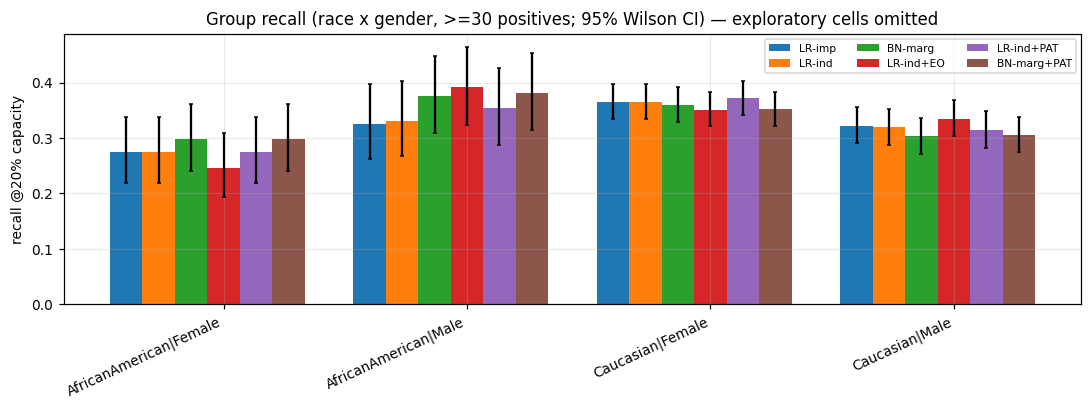

In [18]:
# ============================================================
# 11c. GROUP-LEVEL RESULTS WITH DENOMINATORS, GROUP x MISSINGNESS-PATTERN GAPS, FIGURES
# ============================================================
show_methods = ["LR-imp", "LR-ind", "BN-marg", "LR-ind+EO", "LR-ind+PAT", "BN-marg+PAT"]
gt = {m: group_table(yte, NAT[m]["d"], dte["rg"], RG_NAME).set_index("group") for m in show_methods}
base_tab = gt["LR-ind"][["n", "n_pos", "n_neg", "exploratory"]]
G = pd.concat({m: gt[m]["tpr"] for m in show_methods}, axis=1)
G = pd.concat([base_tab, G], axis=1); savetab(G, "e2_group_recall_race_gender.csv")
print("Recall (TPR) by race x gender at 20% capacity; cells with <30 positives are EXPLORATORY (not used in headline gaps):")
print(G.round(3).to_string())

# group x missingness pattern: gap within each pattern (cells with >=30 positives)
rows = []
for m in ["LR-imp", "LR-ind", "BN-marg", "LR-ind+PAT"]:
    for p, nm in [(0, "A1C not measured"), (1, "A1C measured")]:
        mk = dte["RA"] == p; f = fair_fast(yte[mk], NAT[m]["d"][mk], dte["rg"][mk])
        rows.append(dict(method=m, pattern=nm, n=int(mk.sum()), n_pos=int(yte[mk].sum()), recall=(NAT[m]["d"][mk] * yte[mk]).sum() / yte[mk].sum(),
                         worst_group_recall=f["wgr"], dEOpp_within_pattern=f["dEOpp"]))
PG = pd.DataFrame(rows); savetab(PG, "e2_gaps_within_missingness_patterns.csv", index=False)
print("\nDisparities within the major missingness patterns:"); print(PG.round(4).to_string(index=False))

adequate = G[~G.exploratory].index
fig, ax = plt.subplots(figsize=(10, 3.8)); w = 0.8 / len(show_methods)
for j, m in enumerate(show_methods):
    t = gt[m].loc[adequate]; lo_hi = np.array([wilson(int(round(r.tpr * r.n_pos)), r.n_pos) for r in t.itertuples()])
    ax.bar(np.arange(len(t)) + j * w, t.tpr, w, yerr=[t.tpr - lo_hi[:, 0], lo_hi[:, 1] - t.tpr], capsize=1.5, label=m)
ax.set_xticks(np.arange(len(adequate)) + 0.4, adequate, rotation=25, ha="right"); ax.set_ylabel("recall @20% capacity")
ax.set_title("Group recall (race x gender, >=30 positives; 95% Wilson CI) — exploratory cells omitted"); ax.legend(fontsize=7, ncol=3)
plt.tight_layout(); savefig("fig_e2_group_recall.png"); plt.show()

## 12. Masking generator (semi-synthetic missingness) — Experiments 3 & 4
Controlled missingness is injected into the **initially observed** entries of the two measurements: *number of diagnoses* (all rows eligible) and *A1C* (the naturally observed entries). `rate` = fraction of eligible entries removed. Intercepts are calibrated by bisection so the realised rate matches `rate`; indicators `RA`, `RN` are **recomputed after masking**.

| mechanism | masking probability depends on | class |
|---|---|---|
| `MCAR` | nothing | MCAR |
| `MAR` | age and prior inpatient stay (observed) | MAR |
| `MNAR` | the entry's **own true value** (more diagnoses / A1C > 8 more likely hidden) | MNAR (simulated) |
| `GRP` | recorded race (non-Caucasian more likely masked) — group-dependent masking | MAR given race (synthetic) |

All of these are **synthetic**; their mechanisms are known by construction and must not be read as facts about hospitals.

In [19]:
# ============================================================
# 12a. MASKING GENERATOR + realised-rate checks
# ============================================================
RACE_CAU = RACE_IDX["Caucasian"]
def _calib(lg, target, elig):
    lo, hi = -25., 25.
    for _ in range(50):
        b = (lo + hi) / 2; p = 1 / (1 + np.exp(-(lg[elig] + b)))
        if p.mean() < target: lo = b
        else: hi = b
    return (lo + hi) / 2

def mask_ds(ds, spec, seed):
    if spec is None: return ds
    mech, rate = spec; rng = np.random.default_rng(seed); n = len(ds["y"])
    out = dict(ds); nd_raw = ds["ND_raw"].copy(); nd = ds["ND"].copy(); xa = ds["XA"].copy()
    ageZ = (ds["age_dec"] - 6.4) / 1.6; Hh = (ds["H"] > 0).astype(float)
    ndz = (np.nan_to_num(ds["ND_raw"], nan=7.0) - 7.0) / 2.0
    for var in ("ND", "XA"):
        elig = np.ones(n, bool) if var == "ND" else ds["XA"] >= 0
        if mech == "MCAR": lg = np.zeros(n)
        elif mech == "MAR": lg = 0.9 * ageZ + 0.8 * Hh
        elif mech == "MNAR": lg = 1.2 * ndz if var == "ND" else 1.5 * (ds["XA"] == 2) + 0.5 * (ds["XA"] == 1)
        elif mech == "GRP": lg = 1.5 * (ds["race"] != RACE_CAU)
        else: raise ValueError(mech)
        b = _calib(lg, rate, elig); p = 1 / (1 + np.exp(-(lg + b))); m = elig & (rng.random(n) < p)
        if var == "ND": nd_raw[m] = np.nan; nd[m] = -1
        else: xa[m] = -1
    out.update(ND_raw=nd_raw, ND=nd, XA=xa, RA=(xa >= 0).astype(int), RN=(~np.isnan(nd_raw)).astype(int),
               orig=dict(ND=ds["ND"], XA=ds["XA"]))
    return out

rows = []
for mech in ["MCAR", "MAR", "MNAR", "GRP"]:
    for rate in [0.1, 0.3, 0.5]:
        te = mask_ds(DS["test"], (mech, rate), 0); cau = te["race"] == RACE_CAU; xo = DS["test"]["XA"] >= 0
        rows.append(dict(mech=mech, target=rate, ND_masked=1 - te["RN"].mean(), A1C_masked_of_observed=1 - te["RA"][xo].mean(),
                         ND_masked_Caucasian=1 - te["RN"][cau].mean(), ND_masked_nonCaucasian=1 - te["RN"][~cau].mean(),
                         ND_masked_if_ND_high=1 - te["RN"][DS["test"]["ND_raw"] >= 9].mean(), ND_masked_if_ND_low=1 - te["RN"][DS["test"]["ND_raw"] <= 4].mean()))
MK = pd.DataFrame(rows); savetab(MK, "masking_realised_rates.csv", index=False)
print(MK.round(3).to_string(index=False))
print("\nChecks: realised rate ~ target for every mechanism; MNAR hides high-ND entries more often than low-ND; GRP hides non-Caucasian entries more often.")

mech  target  ND_masked  A1C_masked_of_observed  ND_masked_Caucasian  ND_masked_nonCaucasian  ND_masked_if_ND_high  ND_masked_if_ND_low
MCAR     0.1      0.102                   0.103                0.103                   0.099                 0.102                0.100
MCAR     0.3      0.292                   0.301                0.293                   0.291                 0.290                0.300
MCAR     0.5      0.496                   0.507                0.498                   0.492                 0.494                0.494
 MAR     0.1      0.098                   0.098                0.104                   0.082                 0.112                0.061
 MAR     0.3      0.297                   0.304                0.311                   0.253                 0.330                0.198
 MAR     0.5      0.497                   0.512                0.516                   0.437                 0.536                0.361
MNAR     0.1      0.099                   0.108 

In [20]:
# ============================================================
# 13. SHIFT GRID — train under one mechanism, evaluate under altered mechanisms/rates (+ matched and clean-train controls)
# ============================================================
GRID_MODELS = ["LR-imp", "LR-ind", "BN-base", "BN-marg", "BN-obs", "BN-obs-imp"]
TEST_SPECS = [(m, r) for m in ["MCAR", "MAR", "MNAR", "GRP"] for r in RATES]
sname = lambda s: "natural" if s is None else f"{s[0]}@{int(s[1] * 100)}"
KEEP, MASKACC, GRID = {}, [], []

def metric_row(model, y, s, d, ds):
    r = {k: v for k, v in pred_metrics(y, s, d).items() if k in ("AUROC", "AP", "recall", "precision", "brier")}
    f = fair_fast(y, d, ds["rg"]); r.update(wgr=f["wgr"], dEOpp=f["dEOpp"], dDP=f["dDP"], race_dEOpp=fair_fast(y, d, ds["race"])["dEOpp"])
    r["model"] = model; return r

def run_cell(kind, train_spec, test_specs, seed, keep=False):
    tr, va = mask_ds(DS["train"], train_spec, seed * 1000 + 1), mask_ds(DS["val"], train_spec, seed * 1000 + 2)
    sc = {n: fit_one(n, tr, seed) for n in GRID_MODELS}
    sv = {n: sc[n](va) for n in GRID_MODELS}
    offs = {b: fit_pat_offsets(sv[b], va["y"], va["rg"], va["RA"] + 2 * va["RN"], CAP, seed=seed) for b in ("LR-ind", "BN-marg")}
    xa_mode = int(np.bincount(tr["XA"][tr["XA"] >= 0]).argmax()); nd_mode = int(np.bincount(tr["ND"][tr["ND"] >= 0]).argmax())
    for ts in test_specs:
        te = mask_ds(DS["test"], ts, seed * 1000 + 3); y = te["y"]; pat = te["RA"] + 2 * te["RN"]
        S = {n: sc[n](te) for n in GRID_MODELS}
        for n in GRID_MODELS:
            GRID.append(dict(kind=kind, seed=seed, train=sname(train_spec), test=sname(ts), **metric_row(n, y, S[n], decide_cap(S[n], CAP), te)))
        for b in offs:
            d = decide_cap(S[b], CAP, pat_off_array(offs[b], pat))
            GRID.append(dict(kind=kind, seed=seed, train=sname(train_spec), test=sname(ts), **metric_row(b + "+PAT", y, S[b], d, te)))
        # masked-value predictive accuracy on entries that were ORIGINALLY observed and then masked
        m = sc["BN-marg"].model["cpt"]; o = te["orig"]
        em = (o["XA"] >= 0) & (te["XA"] < 0); en = te["ND"] < 0
        if em.any():
            pr = m["XA"].reshape(-1, 3)[(te["age"][em] * DS["train"]["cards"]["C"] + te["C"][em]) * DS["train"]["cards"]["H"] + te["H"][em]].argmax(1)
            MASKACC.append(dict(kind=kind, seed=seed, train=sname(train_spec), test=sname(ts), var="A1C", n=int(em.sum()), BN_acc=(pr == o["XA"][em]).mean(), mode_acc=(o["XA"][em] == xa_mode).mean()))
        if en.any():
            pr = m["ND"].reshape(-1, DS["train"]["cards"]["ND"])[te["age"][en] * DS["train"]["cards"]["C"] + te["C"][en]].argmax(1)
            MASKACC.append(dict(kind=kind, seed=seed, train=sname(train_spec), test=sname(ts), var="NumDiagnoses", n=int(en.sum()), BN_acc=(pr == o["ND"][en]).mean(), mode_acc=(o["ND"][en] == nd_mode).mean()))
        if keep: KEEP[(seed, sname(train_spec), sname(ts))] = dict(S=S, y=y, rg=te["rg"], pid=te["pid"], pat=pat)

t0 = time.time()
for seed in SEEDS:
    # (A) matched: train and test under the same mechanism/rate (assumption-specific results)
    for mech in ["MCAR", "MAR", "MNAR"]:
        for rate in RATES:
            if (mech, rate) == ("MAR", 0.3): continue
            run_cell("matched", (mech, rate), [(mech, rate)], seed)
    # (B) pre-registered primary design: train MAR@30 -> test under every mechanism/rate
    run_cell("train_MAR30", ("MAR", 0.3), TEST_SPECS, seed, keep=(seed == 0))
    # (C) clean-train control: natural training data -> shifted test
    run_cell("train_natural", None, TEST_SPECS, seed)
    print(f"seed {seed} done ({time.time() - t0:.0f}s)")
GRID = pd.DataFrame(GRID); MASKACC = pd.DataFrame(MASKACC)
savetab(GRID, "e3_e4_shift_grid_all_seeds.csv", index=False); savetab(MASKACC, "e3_masked_value_accuracy.csv", index=False)
print(GRID.shape, "rows")

seed 0 done (49s)
seed 1 done (97s)
seed 2 done (147s)
seed 3 done (195s)
seed 4 done (243s)
(1280, 14) rows


Train under MAR@30 -> test (mean over seeds; sd in brackets)  [worst-group recall | dEOpp | AP | recall@20%]
                      wgr                                     dEOpp                                        AP                                    recall                            
test               GRP@30        MAR@30       MNAR@30        GRP@30        MAR@30       MNAR@30        GRP@30        MAR@30       MNAR@30        GRP@30        MAR@30       MNAR@30
model                                                                                                                                                                              
LR-imp       0.281(0.008)  0.276(0.005)  0.284(0.007)  0.083(0.008)  0.086(0.005)  0.080(0.008)  0.167(0.001)  0.166(0.001)  0.166(0.001)  0.333(0.001)  0.333(0.001)  0.333(0.001)
LR-ind       0.279(0.006)  0.287(0.011)  0.287(0.008)  0.083(0.005)  0.073(0.010)  0.075(0.006)  0.167(0.001)  0.167(0.001)  0.167(0.001)  0.331(0.001)  0.334(0.003)  0.33

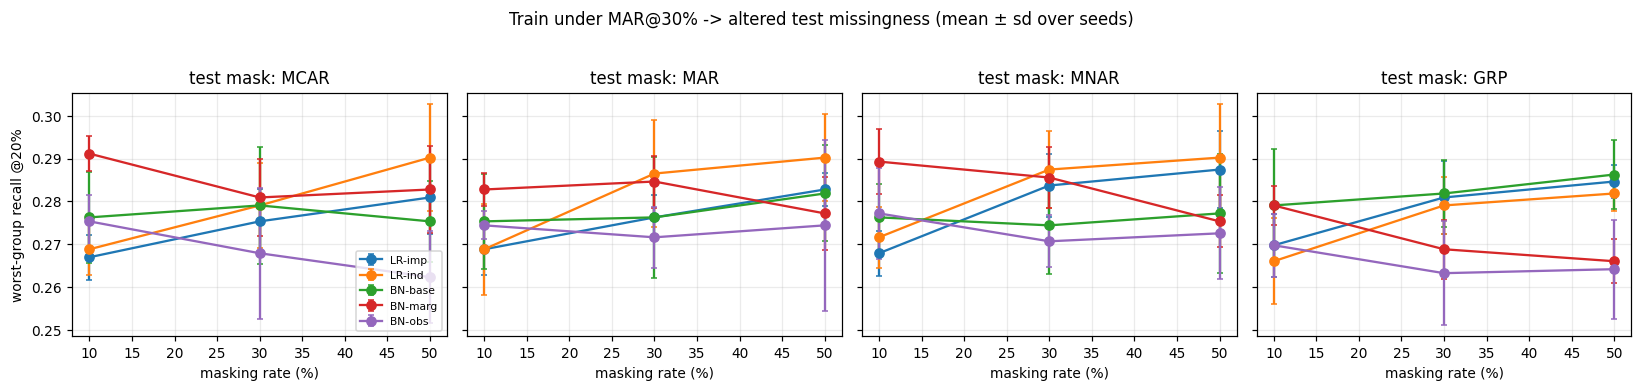


Masked-value predictive accuracy (entries ORIGINALLY observed, then masked) — BN conditional vs mode imputation:
                      BN_acc  mode_acc
var          test                     
A1C          GRP@10    0.484     0.484
             GRP@30    0.488     0.493
             GRP@50    0.486     0.488
             MAR@10    0.422     0.406
             MAR@30    0.418     0.412
             MAR@50    0.436     0.429
             MCAR@10   0.488     0.487
             MCAR@30   0.483     0.483
             MCAR@50   0.483     0.482
             MNAR@10   0.661     0.745
             MNAR@30   0.618     0.693
             MNAR@50   0.571     0.630
NumDiagnoses GRP@10    0.585     0.545
             GRP@30    0.594     0.556
             GRP@50    0.600     0.568
             MAR@10    0.638     0.637
             MAR@30    0.635     0.634
             MAR@50    0.629     0.626
             MCAR@10   0.607     0.575
             MCAR@30   0.608     0.580
             MCAR@50   0.609

In [21]:
# ============================================================
# 13b. SHIFT-GRID SUMMARY (mean ± sd over seeds; EXPLORATORY) and figures
# ============================================================
agg = GRID.groupby(["kind", "train", "test", "model"])[["AP", "recall", "wgr", "dEOpp", "dDP"]].agg(["mean", "std"])
savetab(agg, "e3_e4_shift_grid_summary.csv")
mods = ["LR-imp", "LR-ind", "BN-base", "BN-marg", "BN-obs", "BN-obs-imp", "LR-ind+PAT", "BN-marg+PAT"]
sel = GRID[(GRID.kind == "train_MAR30") & (GRID.test.isin([sname(("MAR", .3)), sname(("MNAR", .3)), sname(("GRP", .3))]))]
print("Train under MAR@30 -> test (mean over seeds; sd in brackets)  [worst-group recall | dEOpp | AP | recall@20%]")
t = sel.groupby(["test", "model"])[["wgr", "dEOpp", "AP", "recall"]].agg(lambda x: f"{x.mean():.3f}({x.std(ddof=0):.3f})").loc[:, :]
print(t.unstack(0).reindex(mods).to_string())

fig, axs = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, mech in zip(axs, ["MCAR", "MAR", "MNAR", "GRP"]):
    for m in ["LR-imp", "LR-ind", "BN-base", "BN-marg", "BN-obs"]:
        q = GRID[(GRID.kind == "train_MAR30") & (GRID.model == m) & GRID.test.str.startswith(mech)].copy(); q["rate"] = q.test.str.split("@").str[1].astype(int)
        g = q.groupby("rate").wgr.agg(["mean", "std"]).fillna(0)
        ax.errorbar(g.index, g["mean"], g["std"], marker="o", capsize=2, label=m)
    ax.set_title(f"test mask: {mech}"); ax.set_xlabel("masking rate (%)")
axs[0].set_ylabel("worst-group recall @20%"); axs[0].legend(fontsize=7)
plt.suptitle("Train under MAR@30% -> altered test missingness (mean ± sd over seeds)", y=1.03); plt.tight_layout(); savefig("fig_e4_shift_worst_group_recall.png"); plt.show()

ma = MASKACC[MASKACC.kind == "train_MAR30"].groupby(["var", "test"])[["BN_acc", "mode_acc"]].mean().round(3)
print("\nMasked-value predictive accuracy (entries ORIGINALLY observed, then masked) — BN conditional vs mode imputation:"); print(ma.to_string())

In [22]:
# ============================================================
# 14. CONFIRMATORY TEST (pre-registered): does explicit availability modelling reduce the DETERIORATION of worst-group recall?
#     train+val MAR@30 -> test MAR@30 (no shift) vs MNAR@30 (shift).  deterioration = wgr(no shift) - wgr(shift).
#     Paired patient bootstrap, 3 comparisons, Holm correction.  Negative difference = BN-marg deteriorates LESS.
# ============================================================
K0, K1 = KEEP[(0, "MAR@30", "MAR@30")], KEEP[(0, "MAR@30", "MNAR@30")]
assert np.array_equal(K0["pid"], K1["pid"]) and np.array_equal(K0["y"], K1["y"]), "same test patients required"
det, ap_det, rec_det = {}, {}, {}
for n in ["BN-marg", "LR-imp", "LR-ind", "BN-base"]:
    b0 = boot_group_stats(K0["y"], decide_cap(K0["S"][n], CAP), K0["rg"], BOOT_INV, BOOT_C)
    b1 = boot_group_stats(K1["y"], decide_cap(K1["S"][n], CAP), K1["rg"], BOOT_INV, BOOT_C)
    det[n] = b0["wgr"] - b1["wgr"]; rec_det[n] = b0["recall"] - b1["recall"]
rows = [dict(model=n, deterioration_wgr=f"{det[n].mean():+.4f} [{ci(det[n])[0]:+.4f},{ci(det[n])[1]:+.4f}]",
             deterioration_recall=f"{rec_det[n].mean():+.4f} [{ci(rec_det[n])[0]:+.4f},{ci(rec_det[n])[1]:+.4f}]") for n in det]
print("Deterioration under MNAR@30 shift (patient bootstrap, 95% interval; positive = worse after shift):")
print(pd.DataFrame(rows).to_string(index=False))

comps = ["LR-imp", "LR-ind", "BN-base"]; res = []
for c in comps:
    dif = det["BN-marg"] - det[c]; lo, hi = ci(dif); res.append(dict(comparison=f"BN-marg vs {c}", effect_diff_in_deterioration=dif.mean(), ci_lo=lo, ci_hi=hi, p_raw=boot_p(dif)))
CF = pd.DataFrame(res); CF["p_holm"] = holm(CF.p_raw.to_numpy()); CF["reject_at_0.05"] = CF.p_holm < 0.05
savetab(CF, "confirmatory_primary_test_holm.csv", index=False)
print("\nCONFIRMATORY FAMILY (Holm, m=3). Effect = difference in deterioration of worst-group recall (negative favours BN-marg):")
print(CF.round(4).to_string(index=False))

per_seed = GRID[(GRID.kind == "train_MAR30") & (GRID.model.isin(["BN-marg", "LR-imp", "LR-ind", "BN-base"]))]
pv = per_seed.pivot_table(index=["model", "seed"], columns="test", values="wgr").reset_index()
pv["deterioration"] = pv["MAR@30"] - pv["MNAR@30"]
print("\nAcross-seed (masking-randomness) variability of the deterioration — NOT a population interval:")
print(pv.groupby("model").deterioration.agg(["mean", "std"]).round(4).to_string())

Deterioration under MNAR@30 shift (patient bootstrap, 95% interval; positive = worse after shift):
  model         deterioration_wgr      deterioration_recall
BN-marg -0.0077 [-0.0281,+0.0094] -0.0005 [-0.0069,+0.0058]
 LR-imp +0.0002 [-0.0149,+0.0152] +0.0018 [-0.0031,+0.0067]
 LR-ind -0.0058 [-0.0318,+0.0105] -0.0036 [-0.0090,+0.0018]
BN-base +0.0046 [-0.0098,+0.0207] +0.0027 [-0.0032,+0.0086]

CONFIRMATORY FAMILY (Holm, m=3). Effect = difference in deterioration of worst-group recall (negative favours BN-marg):
        comparison  effect_diff_in_deterioration   ci_lo  ci_hi  p_raw  p_holm  reject_at_0.05
 BN-marg vs LR-imp                       -0.0080 -0.0316 0.0148 0.6034     1.0           False
 BN-marg vs LR-ind                       -0.0019 -0.0283 0.0300 0.8931     1.0           False
BN-marg vs BN-base                       -0.0123 -0.0367 0.0101 0.3656     1.0           False

Across-seed (masking-randomness) variability of the deterioration — NOT a population interval:
    

             dEOpp               recall                  wgr              
capacity       0.1    0.2    0.3    0.1    0.2    0.3    0.1    0.2    0.3
method                                                                    
BN-base      0.060  0.072  0.114  0.196  0.323  0.432  0.172  0.298  0.372
BN-marg      0.114  0.078  0.119  0.194  0.329  0.430  0.162  0.298  0.367
BN-marg+PAT  0.075  0.084  0.123  0.200  0.327  0.422  0.173  0.298  0.363
HGB-ind      0.110  0.087  0.095  0.197  0.331  0.449  0.121  0.274  0.419
LR-imp       0.059  0.091  0.109  0.196  0.333  0.454  0.153  0.274  0.405
LR-imp+RW    0.059  0.092  0.120  0.196  0.334  0.456  0.153  0.274  0.405
LR-ind       0.051  0.091  0.115  0.196  0.333  0.456  0.158  0.274  0.405
LR-ind+EO    0.180  0.146  0.166  0.193  0.334  0.460  0.107  0.247  0.381
LR-ind+PAT   0.062  0.097  0.072  0.183  0.338  0.441  0.144  0.274  0.395
LR-ind+RW    0.051  0.091  0.115  0.196  0.333  0.456  0.158  0.274  0.405


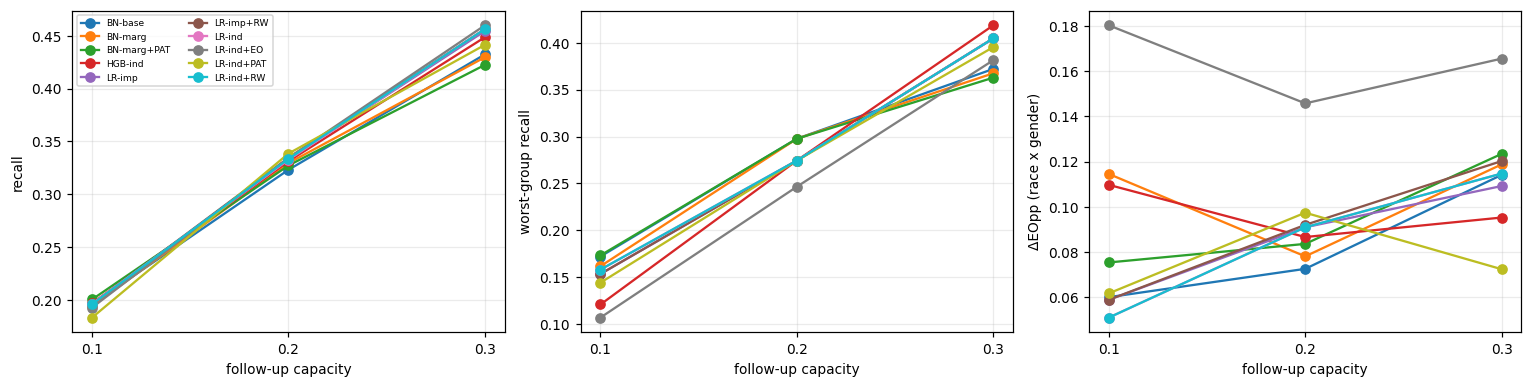


Matched-utility operating points (utility_ok = recall within 0.01 of LR-ind) are flagged in e5_capacity_fairness_utility.csv.


In [23]:
# ============================================================
# 15. EXPERIMENT 5 — FAIRNESS–UTILITY–CAPACITY TRADE-OFFS (natural data; rules re-fitted on VALIDATION at each capacity)
# ============================================================
rows = []
for cap in CAPS:
    S = {n: (NAT[n]["sv"], NAT[n]["st"]) for n in ["LR-imp", "LR-ind", "HGB-ind", "BN-base", "BN-marg", "LR-imp+RW", "LR-ind+RW"]}
    dec = {n: (decide_cap(v[1], cap), False) for n, v in S.items()}
    eo_c = fit_eo_offsets(S["LR-ind"][0], dva["y"], dva["rg"], cap)
    dec["LR-ind+EO"] = (decide_cap(S["LR-ind"][1], cap, eo_off_array(eo_c, dte["rg"])), True)
    for b in ["LR-ind", "BN-marg"]:
        o = fit_pat_offsets(S[b][0], dva["y"], dva["rg"], PAT_va, cap, seed=0)
        dec[b + "+PAT"] = (decide_cap(S[b][1], cap, pat_off_array(o, PAT_te)), False)
    for n, (d, uA) in dec.items():
        base = n.replace("+RW", "").replace("+EO", "").replace("+PAT", "")
        f = fair_fast(yte, d, dte["rg"])
        rows.append(dict(capacity=cap, method=n, uses_race_gender_at_decision=uA, recall=(d * yte).sum() / yte.sum(), precision=(d * yte).sum() / d.sum(),
                         wgr=f["wgr"], dEOpp=f["dEOpp"], dDP=f["dDP"], race_dEOpp=fair_fast(yte, d, dte["race"])["dEOpp"]))
CAPT = pd.DataFrame(rows)
ref = CAPT[CAPT.method == "LR-ind"].set_index("capacity").recall
CAPT["utility_ok"] = [r.recall >= ref[r.capacity] - 0.01 for r in CAPT.itertuples()]
savetab(CAPT, "e5_capacity_fairness_utility.csv", index=False)
print(CAPT.pivot_table(index="method", columns="capacity", values=["recall", "wgr", "dEOpp"]).round(3).to_string())

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for m, t in CAPT.groupby("method"):
    ax[0].plot(t.capacity, t.recall, marker="o", label=m); ax[1].plot(t.capacity, t.wgr, marker="o"); ax[2].plot(t.capacity, t.dEOpp, marker="o")
ax[0].set_ylabel("recall"); ax[1].set_ylabel("worst-group recall"); ax[2].set_ylabel("ΔEOpp (race x gender)")
for a in ax: a.set_xlabel("follow-up capacity"); a.set_xticks(CAPS)
ax[0].legend(fontsize=6, ncol=2); plt.tight_layout(); savefig("fig_e5_capacity_tradeoffs.png"); plt.show()
print("\nMatched-utility operating points (utility_ok = recall within 0.01 of LR-ind) are flagged in e5_capacity_fairness_utility.csv.")

In [24]:
# ============================================================
# 16. REQUIRED ABLATIONS (matched models; paired patient bootstrap on natural data + mean over seeds under the primary shift)
# ============================================================
ABL = [("Remove observation nodes (drop Y->R) : BN-obs -> BN-marg", "BN-obs", "BN-marg"),
       ("Replace marginalisation by single imputation (core) : BN-marg -> BN-base", "BN-marg", "BN-base"),
       ("Replace marginalisation by single imputation (obs model) : BN-obs -> BN-obs-imp", "BN-obs", "BN-obs-imp"),
       ("Remove fairness component (LR) : LR-ind+PAT -> LR-ind", "LR-ind+PAT", "LR-ind"),
       ("Remove fairness component (BN) : BN-marg+PAT -> BN-marg", "BN-marg+PAT", "BN-marg")]
rows = []
for lab, full, abl in ABL:
    r = dict(ablation=lab)
    for met in ["recall", "wgr", "dEOpp"]:
        dif = boot[full][met] - boot[abl][met]; lo, hi = ci(dif); r[f"natural Δ{met} (full-ablated)"] = f"{dif.mean():+.4f} [{lo:+.4f},{hi:+.4f}]"
    sh = GRID[(GRID.kind == "train_MAR30") & (GRID.test == "MNAR@30")].pivot_table(index="seed", columns="model", values=["wgr", "dEOpp"])
    for met in ["wgr", "dEOpp"]:
        r[f"MNAR@30 shift Δ{met} (mean over seeds)"] = float((sh[met][full] - sh[met][abl]).mean())
    rows.append(r)
ABLT = pd.DataFrame(rows).set_index("ablation"); savetab(ABLT, "ablations.csv")
print(ABLT.T.to_string())
print("\nReading guide: for wgr higher is better, for dEOpp lower is better. Intervals that contain 0 mean the component's effect is not distinguishable from noise at this sample size.")

ablation                               Remove observation nodes (drop Y->R) : BN-obs -> BN-marg Replace marginalisation by single imputation (core) : BN-marg -> BN-base Replace marginalisation by single imputation (obs model) : BN-obs -> BN-obs-imp Remove fairness component (LR) : LR-ind+PAT -> LR-ind Remove fairness component (BN) : BN-marg+PAT -> BN-marg
natural Δrecall (full-ablated)                                        -0.0011 [-0.0066,+0.0049]                                                +0.0064 [-0.0018,+0.0146]                                                       +0.0123 [+0.0045,+0.0201]                             +0.0057 [-0.0037,+0.0151]                               -0.0024 [-0.0081,+0.0035]
natural Δwgr (full-ablated)                                           -0.0011 [-0.0188,+0.0175]                                                -0.0002 [-0.0227,+0.0243]                                                       +0.0139 [-0.0086,+0.0437]                             +0.00

In [25]:
# ============================================================
# 17. ROBUSTNESS: alternative discretisation, smoothing strength, unknown-demographic treatment, age audit
# ============================================================
# (a) alternative feature discretisation (age bands x number-of-diagnoses bins), natural and MNAR@30 test, train natural
rows = []
for sch, k in [(3, 3), (5, 3), (3, 5), (5, 5)]:
    D2, _ = make_all_ds(sch, k)
    for mname in ["BN-base", "BN-marg"]:
        sc = fit_one(mname, D2["train"], 0, HP[mname])
        for ts in [None, ("MNAR", 0.3)]:
            te = mask_ds(D2["test"], ts, 3); s = sc(te); d = decide_cap(s, CAP)
            r = metric_row(mname, te["y"], s, d, te); r.update(age_bands=sch, nd_bins=k, test=sname(ts)); rows.append(r)
RB1 = pd.DataFrame(rows); savetab(RB1, "robust_discretisation.csv", index=False)
print("(a) discretisation robustness:"); print(RB1[["model", "age_bands", "nd_bins", "test", "AP", "recall", "wgr", "dEOpp"]].round(4).to_string(index=False))

# (b) smoothing strength of the core BN
rows = []
for sm in [1.0, 5.0, 20.0, 50.0]:
    sc = fit_one("BN-marg", dtr, 0, dict(smooth=sm)); s = sc(dte); d = decide_cap(s, CAP)
    r = metric_row("BN-marg", yte, s, d, dte); r["smooth"] = sm; rows.append(r)
RB2 = pd.DataFrame(rows); savetab(RB2, "robust_smoothing.csv", index=False)
print("\n(b) smoothing-strength robustness (BN-marg, natural test):"); print(RB2[["smooth", "AUROC", "AP", "recall", "wgr", "dEOpp"]].round(4).to_string(index=False))

# (c) alternative treatment of unknown demographic categories in the AUDIT (decisions unchanged)
rows = []
for treat in ["unknown kept as own group", "unknown excluded from audit", "unknown race merged into 'Other'"]:
    race, gen = dte["race"].copy(), dte["gender"].copy(); keep = np.ones(len(yte), bool)
    if treat.startswith("unknown excluded"): keep = (race != 5) & (gen != 2)
    if treat.startswith("unknown race merged"): race = np.where(race == 5, 4, race)
    rg = race * 10 + gen
    for m in ["LR-imp", "LR-ind", "BN-marg", "LR-ind+PAT"]:
        f = fair_fast(yte[keep], NAT[m]["d"][keep], rg[keep]); rows.append(dict(treatment=treat, method=m, wgr=f["wgr"], dEOpp=f["dEOpp"], dDP=f["dDP"]))
RB3 = pd.DataFrame(rows); savetab(RB3, "robust_unknown_demographics.csv", index=False)
print("\n(c) unknown-demographic treatment (headline gaps use cells with >=30 positives):"); print(RB3.pivot(index="method", columns="treatment", values="dEOpp").round(4).to_string())
print("Note: merging 'Unknown' race into 'Other' creates additional cells with >=30 positives, so the headline gap changes because the SET of audited groups changes, not because decisions changed.")

# (d) secondary audit dimension: age bands
rows = []
for m in ["LR-imp", "LR-ind", "BN-marg", "LR-ind+EO", "LR-ind+PAT"]:
    t = group_table(yte, NAT[m]["d"], dte["age"], {0: "<50", 1: "50-69", 2: ">=70"}); f = fairness_summary(t)
    rows.append(dict(method=m, dEOpp_age=f["dEOpp"], worst_recall_age=f["worst_tpr"], dDP_age=f["dDP"], **{f"recall_{r.group}": r.tpr for r in t.itertuples()}))
RB4 = pd.DataFrame(rows); savetab(RB4, "robust_age_audit.csv", index=False)
print("\n(d) age-band audit (secondary dimension; age is also a predictor):"); print(RB4.round(4).to_string(index=False))

(a) discretisation robustness:
  model  age_bands  nd_bins    test     AP  recall    wgr  dEOpp
BN-base          3        3 natural 0.1702  0.3231 0.2977 0.0725
BN-base          3        3 MNAR@30 0.1711  0.3245 0.2837 0.0920
BN-marg          3        3 natural 0.1677  0.3294 0.2977 0.0780
BN-marg          3        3 MNAR@30 0.1672  0.3254 0.2837 0.0864
BN-base          5        3 natural 0.1660  0.3114 0.2744 0.0736
BN-base          5        3 MNAR@30 0.1664  0.3114 0.2651 0.0940
BN-marg          5        3 natural 0.1638  0.3042 0.2698 0.0728
BN-marg          5        3 MNAR@30 0.1652  0.3087 0.2698 0.0589
BN-base          3        5 natural 0.1700  0.3199 0.2837 0.0699
BN-base          3        5 MNAR@30 0.1706  0.3186 0.2698 0.0949
BN-marg          3        5 natural 0.1667  0.3236 0.2791 0.0856
BN-marg          3        5 MNAR@30 0.1664  0.3231 0.2791 0.0800
BN-base          5        5 natural 0.1636  0.3136 0.2744 0.0586
BN-base          5        5 MNAR@30 0.1645  0.3096 0.2512 0

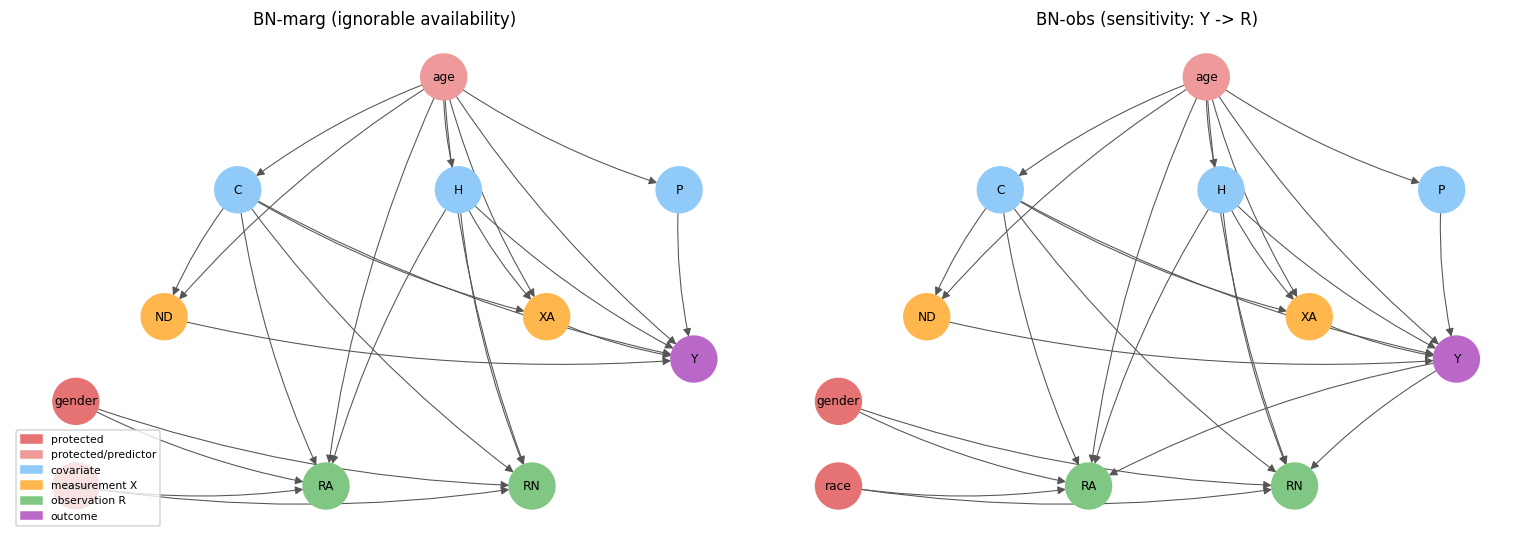

                             statement  BN-marg d-separated  BN-obs d-separated
                         race ⟂ Y | {}                 True                True
                       race ⟂ Y | {RA}                False               False
    race ⟂ Y | {RA, gender, age, C, H}                 True               False
                           RA ⟂ Y | {}                False               False
    RA ⟂ Y | {race, gender, age, C, H}                 True               False
                 XA ⟂ RA | {age, C, H}                 True               False
gender ⟂ Y | {RA, RN, race, age, C, H}                 True               False

Markov blanket of Y:  BN-marg -> ['C', 'H', 'ND', 'P', 'XA', 'age'] 
                      BN-obs  -> ['C', 'H', 'ND', 'P', 'RA', 'RN', 'XA', 'age', 'gender', 'race']
Interpretation: in BN-marg the availability nodes are NOT in Y's Markov blanket, so P(Y|e) ignores them (verified numerically in §9d). In BN-obs, Y has children RA, RN, hence race/gender enter

In [26]:
# ============================================================
# 18. GRAPH ANALYSIS: DAGs, d-separation statements, Markov blankets, evidence propagation under marginalisation
# ============================================================
KIND = dict(race="protected", gender="protected", age="protected/predictor", H="covariate", P="covariate", C="covariate",
            ND="measurement X", XA="measurement X", RA="observation R", RN="observation R", Y="outcome")
COL = {"protected": "#e57373", "protected/predictor": "#ef9a9a", "covariate": "#90caf9", "measurement X": "#ffb74d", "observation R": "#81c784", "outcome": "#ba68c8"}
POS = dict(age=(5, 6), C=(2.2, 4.4), H=(5.2, 4.4), P=(8.2, 4.4), ND=(1.2, 2.6), XA=(6.4, 2.6), Y=(8.4, 2.0), race=(0, 0.2), gender=(0, 1.4), RA=(3.4, 0.2), RN=(6.2, 0.2))
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
models_pg = {}
for ax, (variant, ttl) in zip(axs, [("ign", "BN-marg (ignorable availability)"), ("inf", "BN-obs (sensitivity: Y -> R)")]):
    pa = parents_of(variant); G_ = nx.DiGraph([(p, c) for c in pa for p in pa[c]])
    nx.draw_networkx(G_, POS, ax=ax, node_color=[COL[KIND[n]] for n in G_.nodes], node_size=900, font_size=8, arrows=True, arrowsize=11, edge_color="#555", width=.7, connectionstyle="arc3,rad=0.08")
    ax.set_title(ttl); ax.axis("off")
    models_pg[variant] = to_pgmpy(m_ign_ref if variant == "ign" else m_inf_ref)
import matplotlib.patches as mpatches
axs[0].legend(handles=[mpatches.Patch(color=c, label=k) for k, c in COL.items()], fontsize=7, loc="lower left")
plt.tight_layout(); savefig("fig_graph_dags.png"); plt.show()

def dsep(model, a, b, given):
    return b not in model.active_trail_nodes(a, observed=given)[a]
stmts = [("race", "Y", []), ("race", "Y", ["RA"]), ("race", "Y", ["RA", "gender", "age", "C", "H"]),
         ("RA", "Y", []), ("RA", "Y", ["race", "gender", "age", "C", "H"]), ("XA", "RA", ["age", "C", "H"]),
         ("gender", "Y", ["RA", "RN", "race", "age", "C", "H"])]
rows = []
for a, b, g in stmts:
    rows.append({"statement": f"{a} ⟂ {b} | {{{', '.join(g)}}}", "BN-marg d-separated": dsep(models_pg["ign"], a, b, g), "BN-obs d-separated": dsep(models_pg["inf"], a, b, g)})
DS_T = pd.DataFrame(rows); savetab(DS_T, "dseparation_statements.csv", index=False); print(DS_T.to_string(index=False))
print("\nMarkov blanket of Y:  BN-marg ->", sorted(models_pg["ign"].get_markov_blanket("Y")), "\n                      BN-obs  ->", sorted(models_pg["inf"].get_markov_blanket("Y")))
print("Interpretation: in BN-marg the availability nodes are NOT in Y's Markov blanket, so P(Y|e) ignores them (verified numerically in §9d). "
      "In BN-obs, Y has children RA, RN, hence race/gender enter the blanket as co-parents and conditioning on availability opens collider paths "
      "(explaining away, lab E1): this is the channel through which availability can transmit group information.")
print("These graphs are ASSOCIATIONAL models of recorded data; no causal effect of race/gender/testing is claimed.")

# evidence propagation for one illustrative profile: how marginalisation changes P(Y|e)
def profile(age=2, H=1, P=0, C=0, nd=-1, xa=-1):
    return dict(age=np.array([age]), H=np.array([H]), P=np.array([P]), C=np.array([C]), ND=np.array([nd]), XA=np.array([xa]),
                RA=np.array([int(xa >= 0)]), RN=np.array([int(nd >= 0)]), race=np.array([2]), gender=np.array([0]))
rows = []
for lab, kw in [("A1C=Norm, ND observed(mid)", dict(xa=0, nd=1)), ("A1C=>7", dict(xa=1, nd=1)), ("A1C=>8", dict(xa=2, nd=1)),
                ("A1C missing, ND observed", dict(xa=-1, nd=1)), ("A1C observed, ND missing", dict(xa=1, nd=-1)), ("both missing", dict())]:
    pr = profile(**kw); rows.append(dict(evidence=lab, **{nm: float(bn_proba(m, pr)[0]) for nm, m in [("BN-marg", m_ign_ref), ("BN-obs", m_inf_ref)]}))
EP = pd.DataFrame(rows); savetab(EP, "evidence_propagation_example.csv", index=False)
print("\nP(readmit<30 | evidence) for a profile (age>=70, 1 prior inpatient visit, 0 other prior visits, circulatory diagnosis):"); print(EP.round(4).to_string(index=False))
w = m_ign_ref["cpt"]["XA"][2, 0, 1]; pyx = [float(bn_proba(m_ign_ref, profile(xa=k, nd=1))[0]) for k in range(3)]
print("Caution: BN-obs extrapolates for 'ND missing' (RN=0), a pattern that NEVER occurs in the natural training data, so its CPT there is driven by the smoothing prior "
      "(the large jump above is that artefact, not a clinical signal). BN-obs is only trustworthy for availability patterns seen in training.")
print(f"Marginalisation = convex combination: weights P(A1C|age,C,H)={np.round(w, 3)} x P(Y|A1C=k)={np.round(pyx, 4)} -> {float(w @ np.array(pyx)):.4f} "
      f"(model output {float(bn_proba(m_ign_ref, profile(xa=-1, nd=1))[0]):.4f}; weights over ND re-enter via P(Y|ND))")

         logloss   brier     ECE  mean_pred  prevalence
model                                                  
LR-ind    0.3410  0.0974  0.0068     0.1138      0.1119
HGB-ind   0.3400  0.0971  0.0055     0.1138      0.1119
BN-marg   0.3440  0.0978  0.0145     0.1129      0.1119
BN-obs    0.3432  0.0977  0.0114     0.1121      0.1119

Group calibration-in-the-large by race (exploratory if <30 positives):
  model           group     n  n_pos  observed  predicted  calibration_gap  exploratory
 LR-ind AfricanAmerican  3707    396    0.1068     0.1121           0.0052        False
 LR-ind           Asian   122     10    0.0820     0.1001           0.0182         True
 LR-ind       Caucasian 14886   1707    0.1147     0.1154           0.0007        False
 LR-ind        Hispanic   371     39    0.1051     0.1044          -0.0007        False
 LR-ind           Other   298     26    0.0872     0.1011           0.0138         True
 LR-ind         Unknown   418     38    0.0909     0.0961       

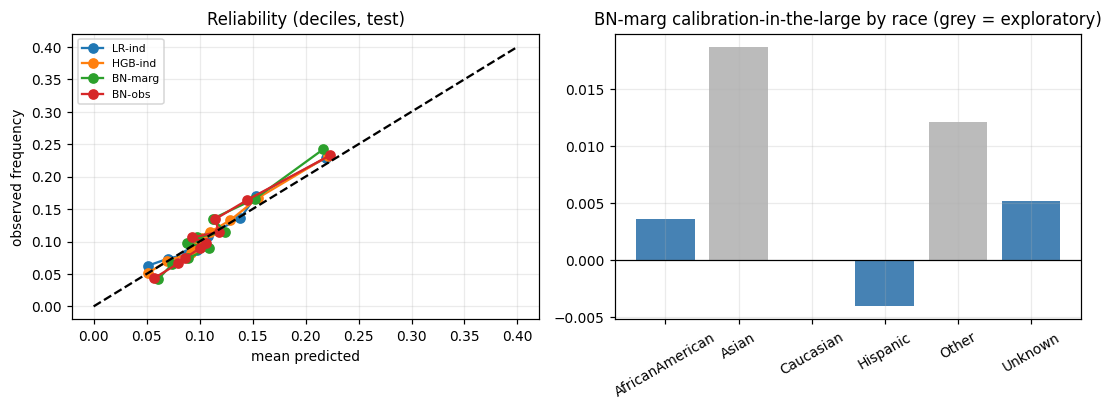

In [27]:
# ============================================================
# 19. PROBABILISTIC METRICS: calibration (overall + by group), log loss, Brier, held-out likelihood of the fitted BN
# ============================================================
from sklearn.calibration import calibration_curve
rows, curves = [], {}
for m in ["LR-ind", "HGB-ind", "BN-marg", "BN-obs"]:
    s = NAT[m]["st"]; p, o = calibration_curve(yte, s, n_bins=10, strategy="quantile"); curves[m] = (o, p)
    rows.append(dict(model=m, logloss=log_loss(yte, np.clip(s, 1e-6, 1 - 1e-6)), brier=brier_score_loss(yte, s), ECE=ece(yte, s), mean_pred=s.mean(), prevalence=yte.mean()))
PM = pd.DataFrame(rows).set_index("model"); savetab(PM, "probabilistic_metrics.csv"); print(PM.round(4).to_string())

rows = []
for m in ["LR-ind", "BN-marg"]:
    for k, nm in enumerate(RACES):
        mk = dte["race"] == k
        rows.append(dict(model=m, group=nm, n=int(mk.sum()), n_pos=int(yte[mk].sum()), observed=yte[mk].mean(), predicted=NAT[m]["st"][mk].mean(),
                         calibration_gap=NAT[m]["st"][mk].mean() - yte[mk].mean(), exploratory=int(yte[mk].sum()) < MIN_N))
GC = pd.DataFrame(rows); savetab(GC, "group_calibration_race.csv", index=False)
print("\nGroup calibration-in-the-large by race (exploratory if <30 positives):"); print(GC.round(4).to_string(index=False))

# held-out likelihood of the fitted BN on OBSERVED measurement values (test, natural data): mean log P(x | parents)
c = m_ign_ref["cpt"]; d = dte; cd_ = d["cards"]
oN, oX = d["ND"] >= 0, d["XA"] >= 0
ll_nd = np.log(c["ND"].reshape(-1, cd_["ND"])[d["age"][oN] * cd_["C"] + d["C"][oN], d["ND"][oN]])
ll_xa = np.log(c["XA"].reshape(-1, cd_["XA"])[(d["age"][oX] * cd_["C"] + d["C"][oX]) * cd_["H"] + d["H"][oX], d["XA"][oX]])
print(f"\nHeld-out mean log-likelihood of observed values under BN-marg:  number-of-diagnoses = {ll_nd.mean():.4f} (n={oN.sum():,}),  A1C = {ll_xa.mean():.4f} (n={oX.sum():,})")
print("Marginal-entropy reference (best constant model):  ND = %.4f,  A1C = %.4f" % (
    -(np.bincount(dtr["ND"]) / len(dtr["ND"]) * np.log(np.bincount(dtr["ND"]) / len(dtr["ND"]))).sum(),
    -(lambda q: (q * np.log(q)).sum())(np.bincount(dtr["XA"][dtr["XA"] >= 0]) / (dtr["XA"] >= 0).sum())))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for m, (o, p) in curves.items(): ax[0].plot(p, o, marker="o", label=m)
ax[0].plot([0, .4], [0, .4], "k--"); ax[0].set_xlabel("mean predicted"); ax[0].set_ylabel("observed frequency"); ax[0].set_title("Reliability (deciles, test)"); ax[0].legend(fontsize=7)
t = GC[GC.model == "BN-marg"]; ax[1].bar(t.group, t.calibration_gap, color=["#bbb" if e else "steelblue" for e in t.exploratory]); ax[1].axhline(0, color="k", lw=.8)
ax[1].set_title("BN-marg calibration-in-the-large by race (grey = exploratory)"); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); savefig("fig_calibration.png"); plt.show()

## 20. Ethics, assumptions and limitations

**Could missingness encode unequal access rather than clinical need?** Yes. "A1C not measured" means *no test was recorded*, which reflects ordering practices, access, documentation and admission pathway as much as clinical status. §6 shows availability differs significantly by race, gender and (most strongly) age. A model that learns availability patterns can therefore transmit unequal access into follow-up decisions; the ignorable `BN-marg` was designed so that availability itself carries no information about readmission beyond observed covariates, and `BN-obs` is reported only as a sensitivity analysis.

**Does the follow-up policy deny care to poorly documented patients?** The simulated policy ranks by estimated risk with a fixed capacity. Patients with many missing fields get scores driven by the marginal/imputed distribution, not by their actual state; the pattern-aware rule (§11) tries to prevent systematic under-selection of the "not measured" pattern but cannot create information that was never recorded. A real service should add a human review route for incompletely documented patients.

**What can be inferred from an incomplete readmission label?** Only *recorded* readmission within 30 days at this health system. Readmissions elsewhere, deaths, or loss to follow-up are invisible; the label is therefore a noisy, administratively-defined proxy and group differences in label quality (e.g. differential access to the same hospital system) would bias every fairness estimate here.

**Honest limits of the evidence.** (i) Only four race×gender cells have ≥30 test positives; every other cell is exploratory and excluded from headline gaps. (ii) Both measurements carry weak predictive signal (AUROC ≈ 0.62 overall), so shifts in their availability can only move group recall slightly; null findings in §14 should be read with the reported interval widths. (iii) MAR for the *unobserved value* is untestable; MNAR/GRP masks are synthetic and their known mechanisms are not facts about hospitals. (iv) The data are 1999–2008 encounters from 130 hospitals with no hospital identifiers; no hospital-level, temporal or prospective claims are made. (v) Learned/assumed DAGs are associational.

In [28]:
# ============================================================
# 21. ASSUMPTIONS REGISTER, MODEL CARD, HEADLINE FINDINGS, OUTPUT BUNDLE
# ============================================================
ASSUMPTIONS = """# Assumptions register — Problem 2
| # | Assumption | Where used | How checked / limitation |
|---|------------|-----------|--------------------------|
| A1 | Recorded '<30' readmission is the outcome; no readmission recorded = Y=0 | label | cannot detect readmission elsewhere |
| A2 | Ignorable availability: RA, RN ⟂ (outcome, unobserved values) | given (race, gender, age, C, H) | BN-marg; CMH test on first encounters (§9b); MAR for the unobserved value itself is UNTESTABLE |
| A3 | Non-ignorable sensitivity: Y -> R | BN-obs | explicit sensitivity model; controlled MNAR simulation (§12-13) |
| A4 | Patient is the independent unit; encounters of one patient are dependent | splits, bootstraps | patient-disjoint split asserted; cluster bootstrap |
| A5 | Race/gender are recorded categories; 'Unknown'/'Invalid' kept as exploratory groups | audit | robustness (c) in §17 |
| A6 | Age band is a clinical predictor AND a secondary audit dimension | models, audit | §17(d) |
| A7 | Synthetic masks (MCAR/MAR/MNAR/GRP) are mechanisms known by construction | §12-14 | labelled synthetic; not facts about hospitals |
| A8 | Fixed follow-up capacity; selection = top-k within the evaluated batch | all decision metrics | capacities 10/20/30% (§15) |
| A9 | Group-aware EO baseline uses race x gender at decision time | baseline only | flagged in tables |
| A10| Associational graphs; no causal claim about race, gender or testing | graph analysis | §18 |
"""
(OUT / "cards" / "assumptions_register.md").write_text(ASSUMPTIONS)

best_prior = E2.loc[["LR-ind", "BN-marg", "LR-ind+PAT"], ["AP", "recall", "rg_worst_tpr", "rg_dEOpp"]].round(4)
MODEL_CARD = f"""# Model card — readmission risk models (Problem 2)
**Intended use**: research benchmark / audit of missing-data handling; NOT for clinical deployment or real follow-up allocation.
**Models**: LR and gradient boosting (imputation +/- indicators), complete-case LR, Bayesian networks BN-base / BN-marg / BN-obs / BN-obs-imp, fairness baselines (reweighing, group-aware EO thresholds) and the proposed missingness-pattern-aware threshold rule.
**Inputs**: age, prior inpatient / outpatient+ED visits, primary-diagnosis group, number of diagnoses, A1C (+ availability indicators). **No scoring model uses race or gender at prediction time.**
**Evaluation**: patient-disjoint train/val/test; capacity {int(CAP*100)}%; patient-cluster bootstrap (B={N_BOOT}); seeds {SEEDS}.
**Headline (natural test)**:
```
{best_prior.to_string()}
```
**Known limitations**: weak discrimination (AUROC ~0.62); few adequately supported race x gender cells; label is recorded readmission only; 1999-2008 data; availability reflects access.
"""
(OUT / "cards" / "model_card.md").write_text(MODEL_CARD)

print("=" * 78); print("HEADLINE FINDINGS (auto-generated from the tables above; read with the interval widths)"); print("=" * 78)
print(E2.loc[["LR-imp", "LR-ind", "HGB-ind", "BN-base", "BN-marg", "BN-obs", "LR-ind+RW", "LR-ind+EO", "LR-ind+PAT", "BN-marg+PAT"], ["AP", "recall", "rg_worst_tpr", "rg_dEOpp", "uses_race_gender_at_decision"]].round(4).to_string())
if CF["reject_at_0.05"].any():
    print("\nConfirmatory test: at least one comparison survives Holm correction ->", CF[CF["reject_at_0.05"]].comparison.tolist())
else:
    print("\nConfirmatory test: NO comparison survives Holm correction. Under this design there is no statistical evidence that explicit availability modelling "
          "(BN-marg) changes the deterioration of worst-group recall relative to imputation / indicator baselines; this is a qualified negative finding "
          "(intervals in confirmatory_primary_test_holm.csv bound the effect that can be excluded).")
pat_gain = E2.loc["LR-ind", "rg_dEOpp"] - E2.loc["LR-ind+PAT", "rg_dEOpp"]
print(f"\nProposed pattern-aware rule vs global rule on LR-ind (natural test): dEOpp change = {-pat_gain:+.4f}; recall change = {E2.loc['LR-ind+PAT','recall'] - E2.loc['LR-ind','recall']:+.4f}  (see bootstrap intervals in e2_bootstrap_intervals.csv)")
print("Group-aware EO baseline changes dEOpp by %+.4f (it uses race x gender at decision time)." % (E2.loc["LR-ind+EO", "rg_dEOpp"] - E2.loc["LR-ind", "rg_dEOpp"]))

# manifest + zip
manifest = sorted(str(p.relative_to(OUT)) for p in OUT.rglob("*") if p.is_file() and p.suffix != ".zip")
(OUT / "manifest.json").write_text(json.dumps(manifest, indent=2))
zp = OUT.parent / "p2_results_bundle.zip"
with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
    for f in OUT.rglob("*"):
        if f.is_file(): z.write(f, f.relative_to(OUT.parent))
print(f"\n{len(manifest)} output files written to {OUT}/  (tables/, figures/, cards/) and zipped to {zp}")
if IN_COLAB:
    from google.colab import files
    # files.download(str(zp))   # uncomment to download the bundle

HEADLINE FINDINGS (auto-generated from the tables above; read with the interval widths)
                 AP  recall  rg_worst_tpr  rg_dEOpp  uses_race_gender_at_decision
method                                                                           
LR-imp       0.1662  0.3330        0.2744    0.0909                         False
LR-ind       0.1665  0.3326        0.2744    0.0909                         False
HGB-ind      0.1806  0.3312        0.2744    0.0866                         False
BN-base      0.1702  0.3231        0.2977    0.0725                         False
BN-marg      0.1677  0.3294        0.2977    0.0780                         False
BN-obs       0.1672  0.3285        0.2977    0.0725                         False
LR-ind+RW    0.1665  0.3335        0.2744    0.0909                         False
LR-ind+EO    0.1665  0.3344        0.2465    0.1458                          True
LR-ind+PAT   0.1665  0.3384        0.2744    0.0973                         False
BN-marg+PA